# SFT and GFN training artifacts

This notebook contains `GFNArtifactsLoader`, `GFNPlottingManager`, `SFTArtifactsLoader`, and `SFTPlottingManager`. Run all cells with the existing **diffusion_gfn** kernel, which supports both plotting and checkpoint inference. The SFT analysis section follows the GFN analysis.

In [28]:
from __future__ import annotations

import ast
import json
import re
import warnings
from pathlib import Path
from typing import Optional, Union

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
import numpy as np
import pandas as pd
import yaml
from IPython import get_ipython
from IPython.display import display

RUN_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / 'results/gfn-final', base / 'infill_subj_arithmetic/results/gfn-final')
                if (candidate / 'eval.py').is_file() and (candidate / 'run_eval.sh').is_file()), None)
if RUN_DIR is None:
    raise FileNotFoundError('Start Jupyter from the repository, experiment, or results directory.')
SFT_RUN_DIR = RUN_DIR.parent / 'output-download-20261111-195140.tBUbSk' / 'stories_sft'
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})

# GFlowNet fine-tuning progress

`GFNArtifactsLoader` loads local logs, Hydra configuration, final metrics and adapter metadata (not model weights). `GFNPlottingManager` provides reusable plotting methods; each returns Matplotlib axes for customization.

**Interpretation:** lower training loss and higher (less negative) log reward are favorable. Logged loss is summed across gradient-accumulation batches; logged reward comes from the last sampled training batch, not a held-out evaluation. The `Eval Reward` field is never updated in the training loop, and story-task `accuracy` returns a placeholder zero: neither measures quality here. LogZ is also constant for this modified-SubTB run. Reward temperature changes during training, so reward trends alone do not establish improved generation quality.

**Parsing:** only runtime output after the training-output marker is parsed, excluding embedded source snapshots. tqdm redraws are deduplicated by completed-step counter; step 1 means the first completed update. Full-precision printed loss and final JSON values replace rounded progress values where available. Separate logs remain separate runs.

Use the **diffusion_gfn** kernel and run all cells. The default path supports starting Jupyter outside this folder; change `RUN_DIR` to analyze another compatible output folder.

In [29]:
class GFNArtifactsLoader:
    """Load scalar training history without loading checkpoints or running inference."""

    NUMBER = r'[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?'
    EVENTS = re.compile(
        rf'(?P<progress>Eval Reward: (?P<eval>{NUMBER}) \| '
        rf'Train Loss: (?P<loss>{NUMBER}), LogZ: (?P<logz>{NUMBER}), '
        rf'Reward: (?P<reward>{NUMBER}):\s*\d+%\|[^\r\n]*?\|\s*'
        r'(?P<step>\d+)/(?P<total>\d+)\s*\[(?P<clock>[^\]]+)\])'
        rf'|(?P<exact>logZ: (?P<exact_logz>{NUMBER}), loss: (?P<exact_loss>{NUMBER}))'
    )
    ANSI = re.compile(r'\x1b\[[0-?]*[ -/]*[@-~]')
    OUTPUT_MARKER = '\n===== Training output =====\n'

    def __init__(self, run_dir: Union[str, Path]):
        self.run_dir = Path(run_dir).expanduser().resolve()
        self.refresh()

    @staticmethod
    def _read_json(path: Path) -> dict:
        if not path.is_file():
            warnings.warn(f'Optional metadata is unavailable: {path}', stacklevel=2)
            return {}
        data = json.loads(path.read_text())
        if not isinstance(data, dict):
            raise ValueError(f'Expected a JSON object: {path}')
        return data

    @staticmethod
    def _elapsed_seconds(clock: str) -> float:
        elapsed = clock.split('<', 1)[0].strip()
        parts = elapsed.split(':')
        if len(parts) not in (2, 3):
            raise ValueError(f'Unsupported tqdm elapsed time: {clock!r}')
        return float(sum(float(part) * 60 ** index for index, part in enumerate(reversed(parts))))

    @classmethod
    def _parse_log(cls, text: str) -> tuple[pd.DataFrame, dict]:
        text = cls.ANSI.sub('', text)
        if cls.OUTPUT_MARKER not in text:
            raise ValueError('Missing training-output marker; refusing to parse embedded source as metrics.')
        runtime = text.split(cls.OUTPUT_MARKER, 1)[1]
        rows, exact = {}, {}
        completed, total_steps = 0, None
        for event in cls.EVENTS.finditer(runtime):
            if event.group('exact') is not None:
                # Printing happens after the update but before tqdm advances its counter.
                exact[completed + 1] = (float(event.group('exact_loss')), float(event.group('exact_logz')))
                continue
            step, total = int(event.group('step')), int(event.group('total'))
            if total_steps is not None and total != total_steps:
                raise ValueError('Multiple training totals in one log; split restarted runs before loading.')
            total_steps = total
            if step < completed:
                raise ValueError('Training counter restarted inside one log.')
            if step == completed:
                continue
            rows[step] = {
                'step': step, 'step_index': step - 1,
                'loss': float(event.group('loss')),
                'log_reward': float(event.group('reward')),
                'logZ': float(event.group('logz')),
                'elapsed_seconds': cls._elapsed_seconds(event.group('clock')),
            }
            completed = step
        if not rows:
            raise ValueError('No completed training updates found in runtime output.')
        for step, (loss, logz) in exact.items():
            if step in rows:
                rows[step].update(loss=loss, logZ=logz)
        frame = pd.DataFrame(rows.values()).sort_values('step').reset_index(drop=True)
        if not np.isfinite(frame[['loss', 'log_reward', 'logZ', 'elapsed_seconds']].to_numpy()).all():
            raise ValueError('Training history contains non-finite values.')
        if frame['elapsed_seconds'].diff().dropna().lt(0).any():
            raise ValueError('Elapsed training time moved backwards.')
        if len(frame) != completed:
            warnings.warn('Some tqdm step snapshots are missing; time differences span those gaps.', stacklevel=2)
        frame['seconds_per_step'] = frame['elapsed_seconds'].diff() / frame['step'].diff()
        frame.loc[0, 'seconds_per_step'] = frame.loc[0, 'elapsed_seconds'] / frame.loc[0, 'step']
        exit_match = re.search(r'^Exit status:\s*(\d+)\s*$', runtime, re.MULTILINE)
        started = re.search(r'^Started: (.+)$', text, re.MULTILINE)
        metadata = {
            'started': started.group(1) if started else None,
            'target_steps': total_steps, 'observed_steps': len(frame), 'last_step': completed,
            'exit_status': int(exit_match.group(1)) if exit_match else None,
            'elapsed_hours': frame['elapsed_seconds'].iloc[-1] / 3600,
            'shutdown_error': 'RunPod SDK stop failed' in runtime,
        }
        return frame, metadata

    def refresh(self) -> GFNArtifactsLoader:
        """Reload files, e.g. after copying newer training output into this directory."""
        if not self.run_dir.is_dir():
            raise FileNotFoundError(self.run_dir)
        log_paths = sorted(self.run_dir.glob('train-*.log'))
        if not log_paths:
            raise FileNotFoundError(f'No train-*.log files in {self.run_dir}')
        active_path = self.run_dir / 'active-log.txt'
        if active_path.is_file():
            # The saved path refers to the remote training host; retain only its filename.
            self.active_run = Path(active_path.read_text().strip()).name
        else:
            warnings.warn('active-log.txt missing; selecting the latest timestamped log.', stacklevel=2)
            self.active_run = log_paths[-1].name
        if self.active_run not in {path.name for path in log_paths}:
            raise FileNotFoundError(f'Active log is not present locally: {self.active_run}')
        config_path = self.run_dir / '.hydra' / 'config.yaml'
        if not config_path.is_file():
            raise FileNotFoundError(config_path)
        self.config = yaml.safe_load(config_path.read_text())
        if not isinstance(self.config, dict):
            raise ValueError(f'Expected a YAML mapping: {config_path}')
        self.final_results = self._read_json(self.run_dir / 'train_results.json')
        self.adapter_config = self._read_json(self.run_dir / 'final_adapter' / 'adapter_config.json')
        histories, run_info = [], []
        for path in log_paths:
            frame, metadata = self._parse_log(path.read_text())
            if path.name == self.active_run:
                if self.final_results:
                    if int(self.final_results['steps']) != int(frame['step'].iloc[-1]):
                        raise ValueError('Final JSON and active-log step counts disagree.')
                    for metric, key in [('loss', 'final_loss'), ('log_reward', 'final_log_reward'), ('logZ', 'final_logZ')]:
                        value = float(self.final_results[key])
                        if not np.isfinite(value) or not np.isclose(frame[metric].iloc[-1], value, rtol=0, atol=0.00051):
                            raise ValueError(f'Final JSON disagrees with active-log {metric}.')
                        frame.loc[frame.index[-1], metric] = value
                status_path = self.run_dir / 'exit-status.txt'
                if status_path.is_file():
                    status = int(status_path.read_text().strip())
                    if metadata['exit_status'] is not None and metadata['exit_status'] != status:
                        raise ValueError('Exit-status file and active log disagree.')
                    metadata['exit_status'] = status
            if metadata['exit_status'] != 0:
                warnings.warn(f'{path.name}: exit status is {metadata["exit_status"]}; completion is not verified.', stacklevel=2)
            if metadata['shutdown_error']:
                warnings.warn(f'{path.name}: training exited, but the log reports a pod-shutdown error.', stacklevel=2)
            frame.insert(0, 'run_name', path.name)
            histories.append(frame)
            run_info.append({'run_name': path.name, 'active': path.name == self.active_run, **metadata})
        self.history = pd.concat(histories, ignore_index=True)
        self.run_info = pd.DataFrame(run_info).set_index('run_name')
        return self

    def get_history(self, run_name: Optional[str] = None) -> pd.DataFrame:
        name = self.active_run if run_name is None else run_name
        if name not in self.run_info.index:
            raise KeyError(f'Unknown run {name!r}; available: {list(self.run_info.index)}')
        return self.history.loc[self.history['run_name'].eq(name)].copy().reset_index(drop=True)

    def progress_summary(self, window: int = 50, run_name: Optional[str] = None) -> pd.DataFrame:
        if not isinstance(window, int) or isinstance(window, bool) or window < 1:
            raise ValueError('window must be a positive integer.')
        history = self.get_history(run_name)
        window = min(window, max(1, len(history) // 2))
        first, last = history.head(window), history.tail(window)
        metrics = ['loss', 'log_reward', 'logZ']
        result = pd.DataFrame({'first_window_mean': first[metrics].mean(), 'last_window_mean': last[metrics].mean()})
        result['change'] = result['last_window_mean'] - result['first_window_mean']
        result['window_observations'] = window
        return result

In [30]:
def _plot_metric_curve(history: pd.DataFrame, metric: str, title: str, window: int,
                       ax: Optional[Axes] = None, log_scale: bool = False) -> Axes:
    if metric not in history or history[metric].dropna().empty:
        raise ValueError(f'No recorded values for {metric}.')
    if not np.isfinite(history[metric].dropna().to_numpy()).all():
        raise ValueError(f'Non-finite values cannot be plotted for {metric}.')
    if log_scale and history[metric].le(0).any():
        raise ValueError(f'Log scale requires strictly positive {metric} values.')
    ax = plt.subplots()[1] if ax is None else ax
    ax.plot(history['step'], history[metric], alpha=0.25, linewidth=0.8, label='Observed')
    smooth = history[metric].rolling(window, min_periods=1).mean()
    ax.plot(history['step'], smooth, linewidth=2, label=f'Trailing mean ({window} observations)')
    ax.set(title=title, xlabel='Completed training updates', ylabel=metric)
    if log_scale:
        ax.set_yscale('log')
    ax.legend(fontsize=8)
    return ax

def _plot_run_comparison(histories: dict[str, pd.DataFrame], metric: str, window: int,
                         ax: Optional[Axes] = None) -> Axes:
    for name, history in histories.items():
        if metric not in history or history[metric].dropna().empty:
            raise ValueError(f'{name}: no recorded values for {metric}.')
    ax = plt.subplots()[1] if ax is None else ax
    for name, history in histories.items():
        ax.plot(history['step'], history[metric].rolling(window, min_periods=1).mean(),
                label=name, marker='.' if len(history) < 5 else None)
    ax.set(title=f'Separate runs: {metric}', xlabel='Completed training updates', ylabel=metric)
    ax.legend(fontsize=8)
    return ax

In [31]:
class GFNPlottingManager:
    """Plot one selected run; smoothing uses trailing observation windows."""

    LABELS = {
        'loss': 'Training loss (lower is better)',
        'log_reward': 'Training log reward (higher is better)',
        'logZ': 'LogZ (normalizer diagnostic)',
        'seconds_per_step': 'Seconds per completed update'
    }

    def __init__(self, runs: GFNArtifactsLoader, run_name: Optional[str] = None, window: int = 50):
        if not isinstance(window, int) or isinstance(window, bool) or window < 1:
            raise ValueError('window must be a positive integer.')
        self.runs = runs
        self.run_name = runs.active_run if run_name is None else run_name
        self.window = window
        runs.get_history(self.run_name)

    @property
    def history(self) -> pd.DataFrame:
        return self.runs.get_history(self.run_name)

    @staticmethod
    def _axis(ax: Optional[Axes]) -> Axes:
        return plt.subplots()[1] if ax is None else ax

    def plot_metric(self, metric: str, ax: Optional[Axes] = None, log_scale: bool = False) -> Axes:
        if metric not in self.LABELS:
            raise KeyError(f'Unsupported metric: {metric}')
        return _plot_metric_curve(self.history, metric, self.LABELS[metric], self.window, ax, log_scale)

    def plot_loss_curve(self, ax: Optional[Axes] = None, log_scale: bool = False) -> Axes:
        return self.plot_metric('loss', ax, log_scale)

    def plot_reward_curve(self, ax: Optional[Axes] = None) -> Axes:
        return self.plot_metric('log_reward', ax)

    def plot_logz_curve(self, ax: Optional[Axes] = None) -> Axes:
        return self.plot_metric('logZ', ax)

    def plot_step_time(self, ax: Optional[Axes] = None) -> Axes:
        return self.plot_metric('seconds_per_step', ax)

    def plot_stability(self, ax: Optional[Axes] = None) -> Axes:
        ax = self._axis(ax)
        history = self.history
        rolling = history['loss'].rolling(self.window, min_periods=2)
        mean, std = rolling.mean(), rolling.std()
        cv = std / mean.abs().replace(0, np.nan)
        if cv.notna().any():
            ax.plot(history['step'], cv)
        else:
            ax.text(0.5, 0.5, 'Insufficient observations or zero mean loss', ha='center', transform=ax.transAxes)
        ax.set(title=f'Loss variability ({self.window}-observation window)',
               xlabel='Completed training updates', ylabel='Rolling std / |rolling mean|')
        return ax

    def plot_loss_reward(self, ax: Optional[Axes] = None) -> Axes:
        ax = self._axis(ax)
        history = self.history
        smooth = history[['loss', 'log_reward']].rolling(self.window, min_periods=1).mean()
        points = ax.scatter(smooth['loss'], smooth['log_reward'], c=history['step'], cmap='viridis', s=12)
        ax.figure.colorbar(points, ax=ax, label='Completed training updates')
        ax.set(title='Smoothed loss versus log reward', xlabel='Training loss', ylabel='Training log reward')
        return ax

    def plot_schedules(self) -> tuple:
        """Reconstruct schedules from the active config and the recorded training-loop formulas."""
        if self.run_name != self.runs.active_run:
            raise ValueError('Root Hydra configuration belongs to the active run, not the other logs.')
        config, history = self.runs.config, self.history
        if int(config['train_steps']) != int(self.runs.run_info.loc[self.run_name, 'target_steps']):
            raise ValueError('Hydra configuration and active-log target steps disagree.')
        schedule = config['reward_sched']
        if schedule['horizon'] <= 0:
            raise ValueError('Reward schedule horizon must be positive.')
        index = history['step_index'].to_numpy()
        learning_rate = np.minimum(index / 20, 1) * config['lr']
        temperature = schedule['start'] + (schedule['end'] - schedule['start']) * np.minimum(index / schedule['horizon'], 1)
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        for ax, values, title, label in zip(axes, [learning_rate, temperature],
                                           ['Learning-rate warmup', 'Reward-temperature schedule'], ['Learning rate', 'Temperature']):
            ax.plot(history['step'], values)
            ax.set(title=title, xlabel='Completed training updates', ylabel=label)
        fig.suptitle('Reconstructed configuration schedules (not measured telemetry)')
        fig.tight_layout()
        return fig, axes

    def plot_run_comparison(self, metric: str = 'loss', ax: Optional[Axes] = None) -> Axes:
        if metric not in self.LABELS:
            raise KeyError(f'Unsupported metric: {metric}')
        histories = {name: self.runs.get_history(name) for name in self.runs.run_info.index}
        return _plot_run_comparison(histories, metric, self.window, ax)

    def plot_dashboard(self) -> tuple:
        fig, axes = plt.subplots(3, 2, figsize=(15, 12))
        methods = [self.plot_loss_curve, self.plot_reward_curve, self.plot_logz_curve,
                   self.plot_stability, self.plot_loss_reward, self.plot_step_time]
        for method, ax in zip(methods, axes.flat):
            method(ax=ax)
        fig.suptitle(f'Fine-tuning diagnostics: {self.run_name}', fontsize=14)
        fig.tight_layout()
        return fig, axes

In [32]:
runs = GFNArtifactsLoader(RUN_DIR)
plots = GFNPlottingManager(runs, window=50)
display(runs.run_info)
display(pd.Series(runs.final_results, name='Final saved metrics').to_frame())
display(runs.progress_summary(window=50))
display(runs.get_history().head())
display(pd.Series({key: runs.config[key] for key in
                   ['loss_type', 'train_steps', 'batch_size', 'grad_acc', 'lr', 'eval_interval', 'use_replay_buffer']},
                  name='Active training configuration').to_frame())
display(pd.Series(runs.adapter_config, name='Adapter metadata').to_frame())

/var/folders/kl/k501rhk96t5bjq54fmkg4j780000gn/T/ipykernel_63875/2114991818.py:17: UserWarning: train-20261112-231010.log: exit status is None; completion is not verified.
  self.refresh()
/var/folders/kl/k501rhk96t5bjq54fmkg4j780000gn/T/ipykernel_63875/2114991818.py:17: UserWarning: train-20261112-234847.log: training exited, but the log reports a pod-shutdown error.
  self.refresh()


,active,started,target_steps,observed_steps,last_step,exit_status,elapsed_hours,shutdown_error
run_name,,,,,,,,
train-20261112-231010.log,False,2026-11-12T23:10:10Z,2,2,2,NaN,0.028056,False
train-20261112-234847.log,True,2026-11-12T23:48:47Z,1000,1000,1000,0.0,13.970000,True


,Final saved metrics
steps,1000.000000
final_loss,3694.777832
final_logZ,0.000000
final_log_reward,-31.950994


,first_window_mean,last_window_mean,change,window_observations
loss,17125.881513,3273.136895,-13852.744617,50
log_reward,-71.704260,-38.144560,33.559700,50
logZ,0.000000,0.000000,0.000000,50


,run_name,step,step_index,loss,log_reward,logZ,elapsed_seconds,seconds_per_step
0,train-20261112-234847.log,1,0,16583.962891,-71.781,0.0,56.0,56.0
1,train-20261112-234847.log,2,1,17517.711000,-64.952,0.0,100.0,44.0
2,train-20261112-234847.log,3,2,19092.863000,-66.236,0.0,145.0,45.0
3,train-20261112-234847.log,4,3,17702.662000,-116.301,0.0,195.0,50.0
4,train-20261112-234847.log,5,4,15857.041000,-27.946,0.0,243.0,48.0


,Active training configuration
loss_type,modified_subtb
train_steps,1000
batch_size,64
grad_acc,16
lr,0.0001
eval_interval,10
use_replay_buffer,True


,Adapter metadata
auto_mapping,"{'base_model_class': 'GPT2LMHeadModel', 'paren..."
base_model_name_or_path,/workspace/gfns-llm/infill_subj_arithmetic/inp...
bias,none
fan_in_fan_out,True
inference_mode,True
init_lora_weights,True
layers_pattern,None
layers_to_transform,None
lora_alpha,16
lora_dropout,0.1


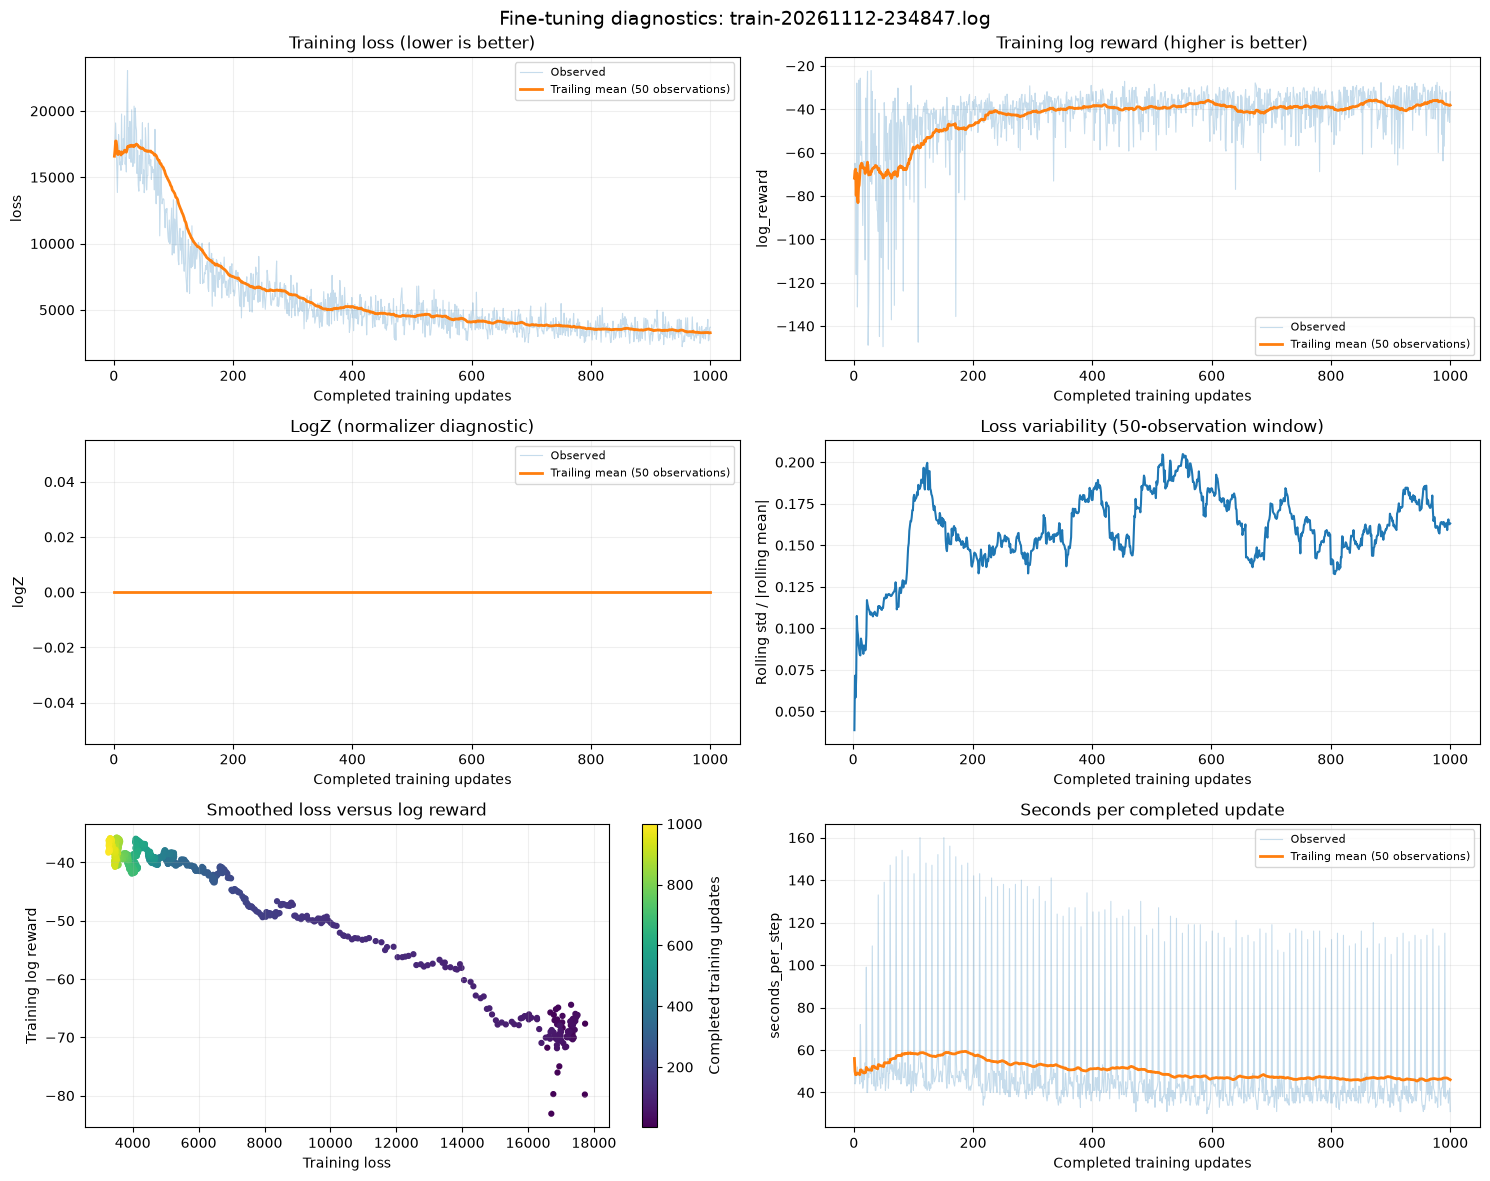

In [33]:
dashboard, dashboard_axes = plots.plot_dashboard()
plt.show()

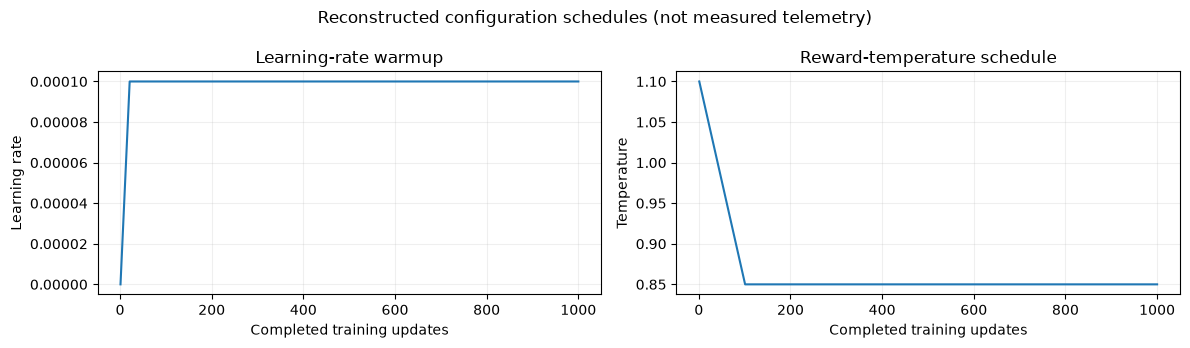

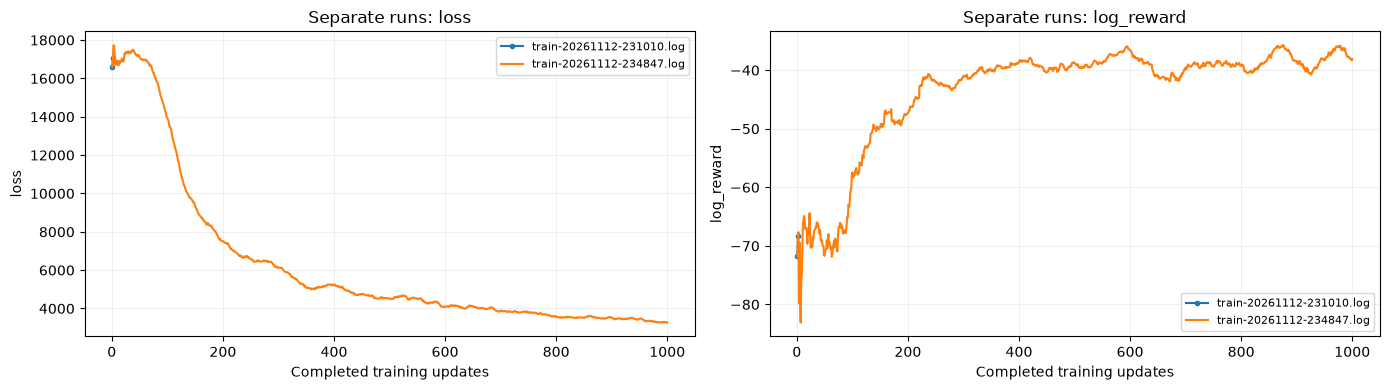

In [34]:
schedule_figure, schedule_axes = plots.plot_schedules()
plt.show()

comparison, axes = plt.subplots(1, 2, figsize=(14, 4))
plots.plot_run_comparison('loss', ax=axes[0])
plots.plot_run_comparison('log_reward', ax=axes[1])
comparison.tight_layout()
plt.show()

# GFN collapse investigation / root-cause EDA

Distinguish numerical divergence, reward plateau, and generation/length collapse. These are descriptive comparisons from one run, not independent-sample significance tests. Different evaluation checkpoints use different prompts.

The analysis verifies the source snapshots saved in the active log. Multiplying reward by temperature undoes scaling of the logged statistic only: it remains a last-microbatch mean over prefixes and zero-filled positions, not terminal reward. Dividing loss by `grad_acc` is a nominal microbatch normalization, not a measurement of gradient norms.

The saved Rich tables contain censored displayed text. Visible EOS and word counts are proxies, not exact generated-token lengths. Repeated EOS strings are decoder/padding artifacts, not evidence that the model repeatedly sampled EOS. No weights or pickle artifacts are loaded.

,Recorded source verified
modified_subtb configured,True
last-batch all-prefix reward logged,True
microbatch gradients summed,True
inverse reward temperature,True
zero-initialized prefix scores,True
inactive prefix scores set to zero,True
sum of token log probabilities,True
replay returns all items below batch size,True
evaluation/checkpoint interval recorded,True


,Scalar diagnostics
non_finite_scalar_count,0.000000
unique_LogZ_values,1.000000
first_to_last_200_mean_loss_reduction_percent,71.257671
fixed_temperature_201_400_reward_mean,-40.418290
fixed_temperature_last_200_reward_mean,-38.135940


,n,loss_mean,reward_mean,reward_std,raw_reward_proxy_mean,loss_std,loss_cv
block,,,,,,,
1,100,15530.626124,-64.57922,30.022670,-63.469595,2686.061604,0.172953
101,100,8419.262685,-48.58877,16.989068,-41.300454,1581.735694,0.187871
201,100,6346.534238,-41.52720,6.100009,-35.298120,972.729203,0.153269
301,100,5179.365328,-39.30938,6.252263,-33.412973,872.330343,0.168424
401,100,4634.199478,-39.58573,7.048540,-33.647870,767.965944,0.165717
501,100,4290.237465,-37.64123,5.546344,-31.995045,852.272939,0.198654
601,100,3997.291383,-40.32094,8.898168,-34.272799,680.123054,0.170146
701,100,3692.402319,-39.24068,7.383136,-33.354578,560.458136,0.151787
801,100,3516.810876,-38.06871,7.041555,-32.358403,559.280473,0.159031


,first_200_mean,last_200_mean,change
loss,11974.944404,3441.877901,-8533.066503
log_reward,-56.583995,-38.135940,18.448055
untempered_logged_reward_proxy,-52.385025,-32.415549,19.969476


,Late slope per 100 updates
loss,-174.418231
log_reward,-0.058334
untempered_logged_reward_proxy,-0.049584


,count,mean,median,max
evaluation_checkpoint_step,,,,
False,900,42.16,42.0,58.0
True,100,123.48,119.0,160.0


,active_score,mean_including_padding
26 active positions (toy),-50.0,-50.000000
6 active + 20 zero positions (toy),-50.0,-11.538462


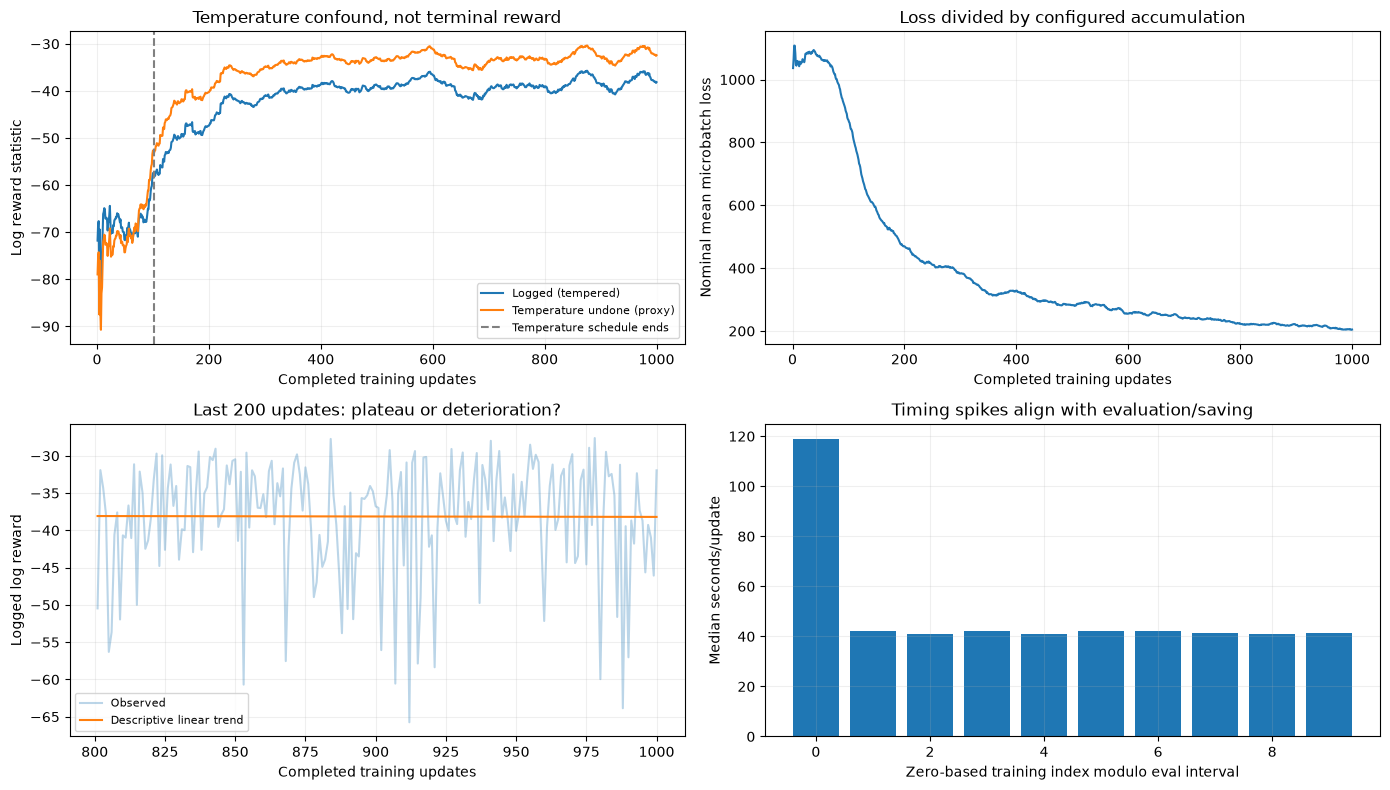

In [35]:
def rca_gfn(runs: GFNArtifactsLoader) -> dict:
    history = runs.get_history()
    config = runs.config
    if len(history) < 400:
        raise ValueError('This early/late RCA requires at least 400 logged updates.')
    log_text = (runs.run_dir / runs.active_run).read_text()
    snapshots = {}
    for filename in ['main.py', 'rewards.py', 'utils.py', 'replay_buffer.py']:
        match = re.search(r'^===== ' + re.escape(filename) + r' =====\n(.*?)(?=\n===== |\Z)', log_text, re.M | re.S)
        if match is None:
            raise ValueError(f'Missing source snapshot: {filename}')
        snapshots[filename] = match.group(1)
    checks = {
        'modified_subtb configured': config['loss_type'] == 'modified_subtb',
        'last-batch all-prefix reward logged': "logrewards.mean().item()" in snapshots['main.py'],
        'microbatch gradients summed': 'batch_loss.mean().backward()' in snapshots['main.py'] and 'loss += batch_loss.mean()' in snapshots['main.py'],
        'inverse reward temperature': '(1./self.temperature)' in snapshots['rewards.py'],
        'zero-initialized prefix scores': 'logrewards = encoded_prompt.new_zeros' in snapshots['utils.py'],
        'inactive prefix scores set to zero': 'torch.where(active_seqs, reward_fn(actions), 0)' in snapshots['utils.py'],
        'sum of token log probabilities': 'res = logPF.sum(dim=-1)' in snapshots['utils.py'],
        'replay returns all items below batch size': 'if len(query_answer_buffer) < batch_size:' in snapshots['replay_buffer.py'],
        'evaluation/checkpoint interval recorded': "if step % config.eval_interval == 0:" in snapshots['main.py'],
    }
    if not all(checks.values()):
        raise ValueError(f'Source assumptions failed: {[key for key, value in checks.items() if not value]}')
    schedule = config['reward_sched']
    history['reward_temperature'] = schedule['start'] + (schedule['end'] - schedule['start']) * np.minimum(history['step_index'] / schedule['horizon'], 1)
    history['untempered_logged_reward_proxy'] = history['log_reward'] * history['reward_temperature']
    history['nominal_microbatch_loss'] = history['loss'] / config['grad_acc']
    history['block'] = (history['step_index'] // 100) * 100 + 1
    blocks = history.groupby('block').agg(n=('step', 'size'), loss_mean=('loss', 'mean'),
        reward_mean=('log_reward', 'mean'), reward_std=('log_reward', 'std'),
        raw_reward_proxy_mean=('untempered_logged_reward_proxy', 'mean'), loss_std=('loss', 'std'))
    blocks['loss_cv'] = blocks['loss_std'] / blocks['loss_mean'].abs()
    early, late = history.head(200), history.tail(200)
    comparison = pd.DataFrame({
        'first_200_mean': early[['loss', 'log_reward', 'untempered_logged_reward_proxy']].mean(),
        'last_200_mean': late[['loss', 'log_reward', 'untempered_logged_reward_proxy']].mean(),
    })
    comparison['change'] = comparison['last_200_mean'] - comparison['first_200_mean']
    late_slopes = pd.Series({metric: np.polyfit(late['step'], late[metric], 1)[0] * 100
                            for metric in ['loss', 'log_reward', 'untempered_logged_reward_proxy']}, name='Late slope per 100 updates')
    interval = int(config['eval_interval'])
    history['evaluation_checkpoint_step'] = history['step_index'].mod(interval).eq(0)
    timing = history.groupby('evaluation_checkpoint_step')['seconds_per_step'].agg(['count', 'mean', 'median', 'max'])
    diagnostics = pd.Series({
        'non_finite_scalar_count': int((~np.isfinite(history[['loss', 'log_reward', 'logZ']].to_numpy())).sum()),
        'unique_LogZ_values': history['logZ'].nunique(),
        'first_to_last_200_mean_loss_reduction_percent': 100 * (1 - late['loss'].mean() / early['loss'].mean()),
        'fixed_temperature_201_400_reward_mean': history.loc[history['step'].between(201, 400), 'log_reward'].mean(),
        'fixed_temperature_last_200_reward_mean': late['log_reward'].mean(),
    }, name='Scalar diagnostics')
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for metric, label in [('log_reward', 'Logged (tempered)'), ('untempered_logged_reward_proxy', 'Temperature undone (proxy)')]:
        axes[0, 0].plot(history['step'], history[metric].rolling(50, min_periods=1).mean(), label=label)
    axes[0, 0].axvline(schedule['horizon'] + 1, color='gray', linestyle='--', label='Temperature schedule ends')
    axes[0, 0].set(title='Temperature confound, not terminal reward', ylabel='Log reward statistic')
    axes[0, 0].legend(fontsize=8)
    axes[0, 1].plot(history['step'], history['nominal_microbatch_loss'].rolling(50, min_periods=1).mean())
    axes[0, 1].set(title='Loss divided by configured accumulation', ylabel='Nominal mean microbatch loss')
    axes[1, 0].plot(late['step'], late['log_reward'], alpha=0.3, label='Observed')
    axes[1, 0].plot(late['step'], np.polyval(np.polyfit(late['step'], late['log_reward'], 1), late['step']), label='Descriptive linear trend')
    axes[1, 0].set(title='Last 200 updates: plateau or deterioration?', ylabel='Logged log reward')
    axes[1, 0].legend(fontsize=8)
    phase = history.groupby(history['step_index'].mod(interval))['seconds_per_step'].median()
    axes[1, 1].bar(phase.index, phase.values)
    axes[1, 1].set(title='Timing spikes align with evaluation/saving', xlabel='Zero-based training index modulo eval interval', ylabel='Median seconds/update')
    for ax in axes.flat:
        if ax is not axes[1, 1]:
            ax.set_xlabel('Completed training updates')
    fig.tight_layout()
    return {'history': history, 'source_checks': pd.Series(checks), 'blocks': blocks,
            'comparison': comparison, 'late_slopes': late_slopes, 'timing': timing,
            'diagnostics': diagnostics, 'figure': fig}

rca = rca_gfn(runs)
display(rca['source_checks'].to_frame('Recorded source verified'))
display(rca['diagnostics'].to_frame())
display(rca['blocks'])
display(rca['comparison'])
display(rca['late_slopes'].to_frame())
display(rca['timing'])

# Illustrative dilution only: identical active scores, different numbers of padded positions.
toy_full = np.full(26, -50.0)
toy_short = np.concatenate([np.full(6, -50.0), np.zeros(20)])
display(pd.DataFrame({'active_score': [-50.0, -50.0], 'mean_including_padding': [toy_full.mean(), toy_short.mean()]},
                     index=['26 active positions (toy)', '6 active + 20 zero positions (toy)']))
plt.show()

displayed_samples  visible_eos_fraction  \
period        split                                            
early_1_101   test                 110              0.427273   
              train                110              0.445455   
late_801_1000 test                 200              0.835000   
              train                200              0.875000   
middle        test                 690              0.860870   
              train                690              0.859420   

                     displayed_word_count_proxy_mean  \
period        split                                    
early_1_101   test                         16.127273   
              train                        16.190909   
late_801_1000 test                          7.835000   
              train                         7.750000   
middle        test                          8.144928   
              train                         7.834783   

                     censored_display_fraction  \
period        split                              
early_1_101   test                    0.409091   
              train                   0.418182   
late_801_1000 test                    0.765000   
              train                   0.740000   
middle        test                    0.784058   
              train                   0.771014   

                     sentence_end_fraction_among_visible_eos  
period        split                                           
early_1_101   test                                  0.659574  
              train                                 0.612245  
late_801_1000 test                                  0.377246  
              train                                 0.422857  
middle        test                                  0.538721  
              train                                 0.527825

,step,split,displayed_rationale
1960,981,test,The family went to the<|endoftext|><|end…
1961,981,test,the entire family went skiing and had a great ...
1962,981,test,The family went to the<|endoftext|><|end…
1963,981,test,The family went to a<|endoftext|><|endof…
1964,981,test,The family went to a<|endoftext|><|endof…
1965,981,test,The family went to the<|endoftext|><|end…
1966,981,test,The family went to the lake and had a relaxing...
1967,981,test,The family went to the<|endoftext|><|end…
1968,981,test,The family grew old and had a<|endoftext|><|en...
1969,981,test,The family went to a wonderful ski trip out We...


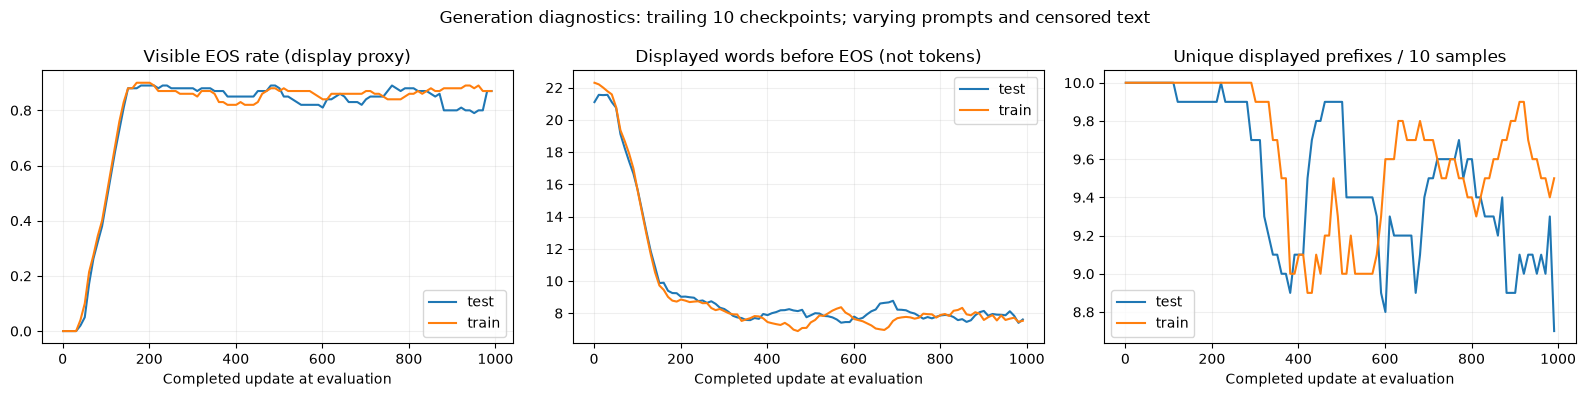

In [36]:
def extract_displayed_gfn_samples(runs: GFNArtifactsLoader) -> pd.DataFrame:
    text = (runs.run_dir / runs.active_run).read_text().split(GFNArtifactsLoader.OUTPUT_MARKER, 1)[1].replace('\r', '\n')
    completed, table_step, table_index = 0, 0, -1
    in_table, current = False, None
    samples = []
    def finish_sample():
        if current is None:
            return
        displayed = ' '.join(chunk for chunk in current['rationale'] if chunk)
        before_eos = displayed.split('<|', 1)[0].strip()
        samples.append({'step': table_step + 1, 'table_id': table_index,
                        'split': 'test' if table_index % 2 == 0 else 'train',
                        'query': ' '.join(current['query']), 'displayed_rationale': displayed,
                        'visible_eos': '<|' in displayed, 'display_censored': '…' in displayed,
                        'visible_word_count_proxy': len(before_eos.split()),
                        'pre_eos_text': before_eos,
                        'sentence_end_before_eos': before_eos.endswith(('.', '!', '?'))})
    for line in text.splitlines():
        progress = re.search(r'Eval Reward:.*?\|\s*(\d+)/(\d+)\s*\[', line)
        if progress:
            completed = int(progress.group(1))
        if line.startswith('┏'):
            if in_table:
                raise ValueError('Unclosed Rich table.')
            in_table, current = True, None
            table_index += 1
            table_step = completed
        elif in_table and line.startswith('│'):
            columns = [value.strip() for value in line.split('│')[1:-1]]
            if len(columns) != 4:
                raise ValueError('Unexpected Rich table layout; do not infer sample metrics.')
            if columns[0].startswith('Beginning:'):
                finish_sample()
                current = {'query': [], 'rationale': []}
            if current is None:
                raise ValueError('Story sample boundary is missing.')
            current['query'].append(columns[0])
            current['rationale'].append(columns[1])
        elif in_table and line.startswith('└'):
            finish_sample()
            in_table, current = False, None
    if in_table or not samples:
        raise ValueError('Missing or incomplete generated-sample tables.')
    frame = pd.DataFrame(samples)
    expected_steps = runs.get_history().loc[lambda h: h['step_index'].mod(runs.config['eval_interval']).eq(0), 'step'].tolist()
    table_steps = frame.groupby('table_id')['step'].first().tolist()
    if table_steps != [step for step in expected_steps for _ in range(2)]:
        raise ValueError('Cannot verify alternating test/train table alignment.')
    if not frame.groupby('table_id').size().eq(10).all():
        raise ValueError('Expected ten displayed examples per evaluation table.')
    return frame

sample_eda = extract_displayed_gfn_samples(runs)
sample_eda['period'] = np.select([sample_eda['step'].le(101), sample_eda['step'].ge(801)], ['early_1_101', 'late_801_1000'], default='middle')
sample_summary = sample_eda.groupby(['period', 'split']).agg(
    displayed_samples=('step', 'size'), visible_eos_fraction=('visible_eos', 'mean'),
    displayed_word_count_proxy_mean=('visible_word_count_proxy', 'mean'),
    censored_display_fraction=('display_censored', 'mean'))
eos_summary = sample_eda.loc[sample_eda['visible_eos']].groupby(['period', 'split'])['sentence_end_before_eos'].mean()
sample_summary['sentence_end_fraction_among_visible_eos'] = eos_summary
per_table = sample_eda.groupby(['table_id', 'step', 'split']).agg(
    visible_eos_fraction=('visible_eos', 'mean'), words_proxy=('visible_word_count_proxy', 'mean'),
    unique_displayed_prefixes=('pre_eos_text', 'nunique')).reset_index()
display(sample_summary)
display(sample_eda.loc[sample_eda['step'].ge(981), ['step', 'split', 'displayed_rationale']].head(20))
sample_figure, sample_axes = plt.subplots(1, 3, figsize=(16, 4))
for split, subset in per_table.groupby('split'):
    for ax, metric, title in zip(sample_axes,
        ['visible_eos_fraction', 'words_proxy', 'unique_displayed_prefixes'],
        ['Visible EOS rate (display proxy)', 'Displayed words before EOS (not tokens)', 'Unique displayed prefixes / 10 samples']):
        ax.plot(subset['step'], subset[metric].rolling(10, min_periods=1).mean(), label=split)
        ax.set(title=title, xlabel='Completed update at evaluation')
        ax.legend()
sample_figure.suptitle('Generation diagnostics: trailing 10 checkpoints; varying prompts and censored text')
sample_figure.tight_layout()
plt.show()

## RCA verdict: suspected short-output degeneration, not numerical divergence

### Observed evidence

- **Numerically stable scalars:** zero non-finite logged scalars; mean loss declines from 11,974.94 in the first 200 updates to 3,441.88 in the last 200 (71.3% lower). This does not prove that gradients or all model parameters remained finite.
- **Reward plateau, not sustained deterioration:** last-200 logged reward averages -38.14, with a descriptive slope of only -0.058 per 100 updates. At fixed temperature, updates 201-400 average -40.42, versus -38.14 late. Continuing loss improvement need not produce better generations.
- **Length/termination warning:** 2,000 displayed examples from 200 tables. Early (updates 1-101) versus late (801-1000): test visible-EOS fraction rises 42.7% to 83.5%, and training 44.5% to 87.5%. Displayed words before EOS fall from 16.13 to 7.84 (test), and 16.19 to 7.75 (train). These are censored-text proxies, not token-length estimates or a matched-prompt causal test.
- **Unfinished endings:** among examples with visible EOS, a sentence-ending punctuation mark precedes EOS in 66.0% early versus 37.7% late test samples, and 61.2% versus 42.3% for training. At update 981, repeated test prefixes include `The family went to the` and `The family went to a`, followed by EOS. Punctuation is only a heuristic, but the displayed fragments are a qualitative warning.
- **Some displayed repetition, not proven global mode collapse:** mean unique displayed prefixes per ten-example table decreases from 10.0 early to 9.225 late. Prompts vary and tables are censored; this cannot establish full-output diversity or distributional collapse.

### Root-cause candidates, ranked

1. **Length-biased reward is the strongest mechanism consistent with the samples.** [score_fast](../../utils.py) sums non-positive token log-probabilities and excludes EOS from the score. The configured frozen-model reward has no active per-token length normalization in this branch. Longer continuations generally accumulate additional negative terms, although changes to ending likelihood can offset that penalty. Training masks EOS only for the first five generated tokens; the [evaluation generator](../../utils.py) has no matching minimum-length mask. This encourages investigating short or generic rationales, but is not a proven causal attribution.
2. **The reward plot overstates interpretability.** [main.py](../../main.py) logs `logrewards.mean()` from the final microbatch, averaging scores for prefixes and inactive zeros, rather than terminal rewards over all 16 microbatches. [ReplayBuffer.sample](../../replay_buffer.py) returns all stored trajectories when fewer than the requested 64 exist; the buffer capacity is 25 per prompt, and replay score arrays may be shorter than fresh arrays. Shorter sequences, zero padding, and replay/fresh mixtures can change this mean without a matching terminal-quality improvement. Temperature undoing alone cannot repair those confounds.
3. **Loss normalization is a secondary optimization risk, not an established cause.** Microbatch gradients are summed without dividing by accumulation count (16); loss is also logged as a sum. This explains part of its numerical scale. AdamW is adaptive, so this must not be interpreted as exactly 16 times the effective learning rate. Gradient norms and clipped fractions were not saved.

### Features that are not evidence of collapse

- **Flat LogZ:** the active modified-SubTB loss does not contain LogZ, so this parameter has no gradient from that objective. Its constant zero value is expected for this implementation.
- **Timing spikes:** evaluation/checkpoint updates have median duration 119 seconds versus 42 seconds otherwise; their index phase matches the every-ten-update generation and saving branch. This is overhead, not optimizer instability.
- **Repeated `<|endoftext|>` in tables:** decoding preserves padded EOS positions after termination; do not count these strings as generated-token repetition.
- **SFT overfitting:** the SFT training loss reduction cannot establish or rule out overfitting without held-out loss. Its objective is not numerically comparable to the GFN objective.

### Confirmation and remediation sequence (training code is unchanged)

1. Compare the saved SFT baseline and final GFN adapter on the **same fixed held-out prompts**, evaluation temperature, length limits, and inference/eval mode. Save structured JSONL with token IDs, first-EOS position, terminal frozen-model score, ending-conditional score, normalized score, and full text. Exact length distributions, unfinished-output rates, within-prompt duplicate rates, and human coherence/completion judgments can confirm or refute degeneration. Intermediate checkpoint comparisons require obtaining those checkpoints.
2. Log terminal-only rewards, active-prefix rewards, zero-padding fraction, behavior-policy source, actual batch size, all-microbatch means, and gradient norms separately. Keep reward temperature explicit. Record a real held-out metric instead of zero evaluation placeholders.
3. Run controlled ablations: consistent train/evaluation EOS constraints, and a deliberately redesigned length-aware/ending-focused reward. Changing reward normalization changes the target distribution and requires validation, not a silent plotting fix. Normalize accumulated gradients if mean-microbatch optimization is intended, then retune only after checking behavior.

**Bottom line:** the curves do not show an exploding optimizer, but the sample EDA supports suspicion of short, sometimes incomplete continuations with limited displayed repetition. Reward design and logging confounds are evidenced mechanisms; a matched-prompt, terminal-score evaluation is needed before calling this confirmed mode collapse.

## Reuse and limitations

- Individual plots: `plots.plot_loss_curve(log_scale=True)`, `plots.plot_reward_curve()`, `plots.plot_logz_curve()`, `plots.plot_stability()`, `plots.plot_loss_reward()`, `plots.plot_step_time()`; then `plt.show()`.
- Select another log with `GFNPlottingManager(runs, run_name='train-20261112-231010.log', window=2)`; histories are never concatenated into one curve. The short run has no recorded completion status.
- Access loaded data through `runs.history`, `runs.get_history()`, `runs.config`, `runs.final_results`, `runs.adapter_config` and `runs.run_info`. Root config/final metadata belong only to the active run. Call `runs.refresh()` to reload local files.
- Save a figure if needed: `dashboard.savefig(RUN_DIR / 'training_progress.png', dpi=160, bbox_inches='tight')`.
- Smoothing is trailing, with partial windows at the beginning; it is not a confidence interval. Runtime is parsed from rounded tqdm elapsed times and includes evaluations/checkpoint saves.
- No held-out quality, diversity, KL divergence or gradient-norm history was logged. Those plots require additional telemetry; zero evaluation placeholders must not be substituted. The completed log also reports a pod-shutdown failure despite training exit status 0; this is exposed in the run table and warning.

# Supervised fine-tuning progress

`SFTArtifactsLoader` reads the downloaded SFT logs, final results, model configuration, and tokenizer metadata without loading model weights or unpickling `training_args.bin`. Edit `SFT_RUN_DIR` in the imports cell to select a different compatible output folder.

Hugging Face Trainer prints metric dictionaries **after** advancing its completed-step counter (unlike the GFN progress descriptions). The loader associates each dictionary with that counter, ignores download/preprocessing progress bars, and keeps interrupted runs separate. `train_results.json` reports the **whole-run mean loss**, not the final-step loss; it must not overwrite the loss curve's endpoint.

`SFTPlottingManager` plots training loss, recorded learning rate, loss by epoch, step timing, and `exp(loss)` as a **training perplexity proxy**. This proxy uses rounded, training-batch/logging-window losses; it is not held-out or corpus-level perplexity. SFT reward and held-out evaluation metrics are not present in these artifacts. Completion summaries do not prove that a process exited successfully when its exit status was not captured.

In [37]:
class SFTArtifactsLoader:
    """Load Hugging Face Trainer scalar dictionaries and local SFT metadata."""

    PROGRESS = re.compile(r'^\s*\d+%\|[^\n]*?\|\s*(\d+)/(\d+)\s*\[([^\]]+)\]')
    METRICS = ('loss', 'learning_rate', 'epoch', 'eval_loss', 'grad_norm')

    def __init__(self, run_dir: Union[str, Path]):
        self.run_dir = Path(run_dir).expanduser().resolve()
        self.refresh()

    @classmethod
    def _parse_log(cls, text: str) -> tuple[pd.DataFrame, dict]:
        text = GFNArtifactsLoader.ANSI.sub('', text).replace('\r\n', '\n').replace('\r', '\n')
        if GFNArtifactsLoader.OUTPUT_MARKER not in text:
            raise ValueError('Missing training-output marker; refusing to parse embedded source as metrics.')
        runtime = text.split(GFNArtifactsLoader.OUTPUT_MARKER, 1)[1]
        rows, elapsed_by_step, summary = {}, {}, {}
        completed, total_steps = 0, None
        for line in runtime.splitlines():
            progress = cls.PROGRESS.match(line)
            if progress:
                step, total = int(progress.group(1)), int(progress.group(2))
                if total_steps is not None and total != total_steps:
                    raise ValueError('Multiple training totals in one SFT log; split restarted runs.')
                if step < completed:
                    raise ValueError('Training counter restarted inside one SFT log.')
                total_steps = total
                if step > completed:
                    elapsed_by_step[step] = GFNArtifactsLoader._elapsed_seconds(progress.group(3))
                    completed = step
                continue
            line = line.strip()
            if not (line.startswith('{') and line.endswith('}')):
                continue
            record = ast.literal_eval(line)
            if not isinstance(record, dict):
                raise ValueError('Expected a Trainer metric dictionary.')
            if 'train_loss' in record:
                summary.update(record)
            if 'loss' not in record and 'eval_loss' not in record:
                continue
            step = record.get('step', completed)
            if isinstance(step, bool) or not isinstance(step, int) or step < 1:
                raise ValueError('Cannot associate Trainer metrics with a completed training step.')
            if step not in rows:
                rows[step] = {'step': step, 'step_index': step - 1,
                              'elapsed_seconds': elapsed_by_step.get(step, np.nan)}
            for metric in cls.METRICS:
                if metric in record:
                    value = float(record[metric])
                    if not np.isfinite(value):
                        raise ValueError(f'SFT metrics contain non-finite {metric} at step {step}.')
                    rows[step][metric] = value
        if not rows:
            raise ValueError('No completed SFT metric records found in runtime output.')
        frame = pd.DataFrame(rows.values()).sort_values('step').reset_index(drop=True)
        if frame['elapsed_seconds'].isna().any():
            warnings.warn('Some SFT metrics have no matching tqdm timestamps; timing plots may be unavailable.', stacklevel=2)
        if frame['elapsed_seconds'].diff().dropna().lt(0).any():
            raise ValueError('Elapsed SFT training time moved backwards.')
        frame['seconds_per_step'] = frame['elapsed_seconds'].diff() / frame['step'].diff()
        frame.loc[0, 'seconds_per_step'] = frame.loc[0, 'elapsed_seconds'] / frame.loc[0, 'step']
        exit_match = re.search(r'^Exit status:\s*(\d+)\s*$', runtime, re.MULTILINE)
        started = re.search(r'^Started: (.+)$', text, re.MULTILINE)
        return frame, {
            'started': started.group(1) if started else None,
            'target_steps': total_steps, 'observed_steps': len(frame), 'last_step': int(frame['step'].iloc[-1]),
            'exit_status': int(exit_match.group(1)) if exit_match else None,
            'training_summary_present': bool(summary),
            'training_mean_loss': summary.get('train_loss', np.nan),
            'elapsed_hours': frame['elapsed_seconds'].iloc[-1] / 3600,
            'shutdown_error': 'RunPod SDK stop failed' in runtime,
            'summary': summary,
        }

    def refresh(self) -> SFTArtifactsLoader:
        if not self.run_dir.is_dir():
            raise FileNotFoundError(self.run_dir)
        log_paths = sorted(self.run_dir.glob('train-*.log'))
        if not log_paths:
            raise FileNotFoundError(f'No train-*.log files in {self.run_dir}')
        active_path = self.run_dir / 'active-log.txt'
        if active_path.is_file():
            self.active_run = Path(active_path.read_text().strip()).name
        else:
            warnings.warn('active-log.txt missing; selecting the latest timestamped SFT log.', stacklevel=2)
            self.active_run = log_paths[-1].name
        if self.active_run not in {path.name for path in log_paths}:
            raise FileNotFoundError(f'Active SFT log is not present locally: {self.active_run}')
        self.final_results = GFNArtifactsLoader._read_json(self.run_dir / 'train_results.json')
        self.config = GFNArtifactsLoader._read_json(self.run_dir / 'config.json')
        self.tokenizer_config = GFNArtifactsLoader._read_json(self.run_dir / 'tokenizer_config.json')
        histories, run_info = [], []
        for path in log_paths:
            frame, metadata = self._parse_log(path.read_text())
            summary = metadata.pop('summary')
            if path.name == self.active_run and self.final_results:
                if int(self.final_results['global_step']) != int(frame['step'].iloc[-1]):
                    raise ValueError('SFT final JSON and active-log step counts disagree.')
                for metric in ('train_loss', 'train_runtime'):
                    if metric in summary and not np.isclose(float(summary[metric]), float(self.final_results[metric]), rtol=0, atol=1e-6):
                        raise ValueError(f'SFT final JSON disagrees with the active-log {metric}.')
            if metadata['exit_status'] != 0:
                warnings.warn(f'{path.name}: process exit status is {metadata["exit_status"]}; successful exit is not verified.', stacklevel=2)
            if metadata['shutdown_error']:
                warnings.warn(f'{path.name}: pod-shutdown error recorded.', stacklevel=2)
            frame.insert(0, 'run_name', path.name)
            histories.append(frame)
            run_info.append({'run_name': path.name, 'active': path.name == self.active_run, **metadata})
        self.history = pd.concat(histories, ignore_index=True)
        self.run_info = pd.DataFrame(run_info).set_index('run_name')
        return self

    def get_history(self, run_name: Optional[str] = None) -> pd.DataFrame:
        name = self.active_run if run_name is None else run_name
        if name not in self.run_info.index:
            raise KeyError(f'Unknown SFT run {name!r}; available: {list(self.run_info.index)}')
        return self.history.loc[self.history['run_name'].eq(name)].copy().reset_index(drop=True)

    def progress_summary(self, window: int = 25, run_name: Optional[str] = None) -> pd.DataFrame:
        if not isinstance(window, int) or isinstance(window, bool) or window < 1:
            raise ValueError('window must be a positive integer.')
        history = self.get_history(run_name)
        window = min(window, max(1, len(history) // 2))
        metrics = [metric for metric in self.METRICS if metric in history]
        result = pd.DataFrame({'first_window_mean': history.head(window)[metrics].mean(),
                               'last_window_mean': history.tail(window)[metrics].mean()})
        result['change'] = result['last_window_mean'] - result['first_window_mean']
        result['window_observations'] = window
        return result

In [38]:
class SFTPlottingManager:
    """Plot recorded SFT training metrics, keeping runs separate."""

    LABELS = {'loss': 'SFT training loss (lower is better)', 'learning_rate': 'Recorded learning rate',
              'epoch': 'Training epoch', 'eval_loss': 'Recorded evaluation loss', 'grad_norm': 'Recorded gradient norm',
              'seconds_per_step': 'Seconds per completed update'}

    def __init__(self, runs: SFTArtifactsLoader, run_name: Optional[str] = None, window: int = 25):
        if not isinstance(window, int) or isinstance(window, bool) or window < 1:
            raise ValueError('window must be a positive integer.')
        self.runs = runs
        self.run_name = runs.active_run if run_name is None else run_name
        self.window = window
        runs.get_history(self.run_name)

    @property
    def history(self) -> pd.DataFrame:
        return self.runs.get_history(self.run_name)

    def plot_metric(self, metric: str, ax: Optional[Axes] = None, log_scale: bool = False) -> Axes:
        if metric not in self.LABELS:
            raise KeyError(f'Unsupported SFT metric: {metric}')
        return _plot_metric_curve(self.history, metric, self.LABELS[metric], self.window, ax, log_scale)

    def plot_loss_curve(self, ax: Optional[Axes] = None, log_scale: bool = False) -> Axes:
        return self.plot_metric('loss', ax, log_scale)

    def plot_learning_rate_curve(self, ax: Optional[Axes] = None) -> Axes:
        return self.plot_metric('learning_rate', ax)

    def plot_step_time(self, ax: Optional[Axes] = None) -> Axes:
        return self.plot_metric('seconds_per_step', ax)

    def plot_perplexity_curve(self, ax: Optional[Axes] = None, log_scale: bool = False) -> Axes:
        history = self.history
        if 'loss' not in history or history['loss'].dropna().empty:
            raise ValueError('Training loss is unavailable for the perplexity proxy.')
        if history['loss'].gt(np.log(np.finfo(float).max)).any():
            raise ValueError('Exponentiating training loss would overflow the perplexity proxy.')
        history['training_perplexity_proxy'] = np.exp(history['loss'])
        return _plot_metric_curve(history, 'training_perplexity_proxy', 'Training perplexity proxy: exp(logged loss)',
                                  self.window, ax, log_scale)

    def plot_loss_by_epoch(self, ax: Optional[Axes] = None) -> Axes:
        history = self.history
        if 'epoch' not in history or history['epoch'].isna().any():
            raise ValueError('Recorded epochs are unavailable for the loss-by-epoch plot.')
        history['step'] = history['epoch']
        ax = _plot_metric_curve(history, 'loss', 'SFT training loss by epoch', self.window, ax)
        ax.set_xlabel('Recorded training epoch')
        return ax

    def plot_run_comparison(self, metric: str = 'loss', ax: Optional[Axes] = None) -> Axes:
        if metric not in self.LABELS:
            raise KeyError(f'Unsupported SFT metric: {metric}')
        histories = {name: self.runs.get_history(name) for name in self.runs.run_info.index}
        return _plot_run_comparison(histories, metric, self.window, ax)

    def plot_dashboard(self) -> tuple:
        fig, axes = plt.subplots(2, 2, figsize=(14, 8))
        for method, ax in zip([self.plot_loss_curve, self.plot_learning_rate_curve,
                               self.plot_perplexity_curve, self.plot_step_time], axes.flat):
            method(ax=ax)
        fig.suptitle(f'SFT diagnostics: {self.run_name}', fontsize=14)
        fig.tight_layout()
        return fig, axes

In [39]:
sft_runs = SFTArtifactsLoader(SFT_RUN_DIR)
sft_plots = SFTPlottingManager(sft_runs, window=25)
display(sft_runs.run_info)
display(pd.Series(sft_runs.final_results, name='SFT whole-run metrics').to_frame())
display(sft_runs.progress_summary())
display(sft_runs.get_history().head())
display(pd.Series({key: sft_runs.config[key] for key in ['model_type', 'n_layer', 'n_embd', 'vocab_size']},
                  name='SFT model configuration').to_frame())

/var/folders/kl/k501rhk96t5bjq54fmkg4j780000gn/T/ipykernel_63875/2089260403.py:9: UserWarning: train-20261112-004520.log: process exit status is 137; successful exit is not verified.
  self.refresh()
/var/folders/kl/k501rhk96t5bjq54fmkg4j780000gn/T/ipykernel_63875/2089260403.py:9: UserWarning: train-20261112-005753.log: process exit status is None; successful exit is not verified.
  self.refresh()
/var/folders/kl/k501rhk96t5bjq54fmkg4j780000gn/T/ipykernel_63875/2089260403.py:9: UserWarning: train-20261112-010639.log: process exit status is None; successful exit is not verified.
  self.refresh()


,active,started,target_steps,observed_steps,last_step,exit_status,training_summary_present,training_mean_loss,elapsed_hours,shutdown_error
run_name,,,,,,,,,,
train-20261112-004520.log,False,2026-11-12T00:45:20Z,50,26,26,137.0,False,NaN,0.134444,False
train-20261112-005753.log,False,2026-11-12T00:57:53Z,1,1,1,NaN,True,3.017833,0.005000,False
train-20261112-010639.log,True,2026-11-12T01:06:39Z,500,500,500,NaN,True,0.921300,2.594444,False


,SFT whole-run metrics
epoch,19.441069
global_step,500.000000
train_loss,0.921300
train_runtime,9353.521800
train_samples_per_second,112.610000
train_steps_per_second,0.053000


,first_window_mean,last_window_mean,change,window_observations
loss,3.761604,0.200140,-3.561464,25
learning_rate,0.000487,0.000012,-0.000475,25
epoch,0.505600,18.974400,18.468800,25


,run_name,step,step_index,elapsed_seconds,loss,learning_rate,epoch,seconds_per_step
0,train-20261112-010639.log,1,0,20.0,3.0178,0.000499,0.04,20.0
1,train-20261112-010639.log,2,1,38.0,8.3855,0.000498,0.08,18.0
2,train-20261112-010639.log,3,2,57.0,9.0925,0.000497,0.12,19.0
3,train-20261112-010639.log,4,3,76.0,6.1849,0.000496,0.16,19.0
4,train-20261112-010639.log,5,4,94.0,5.3156,0.000495,0.19,18.0


,SFT model configuration
model_type,gpt2
n_layer,36
n_embd,1280
vocab_size,50257


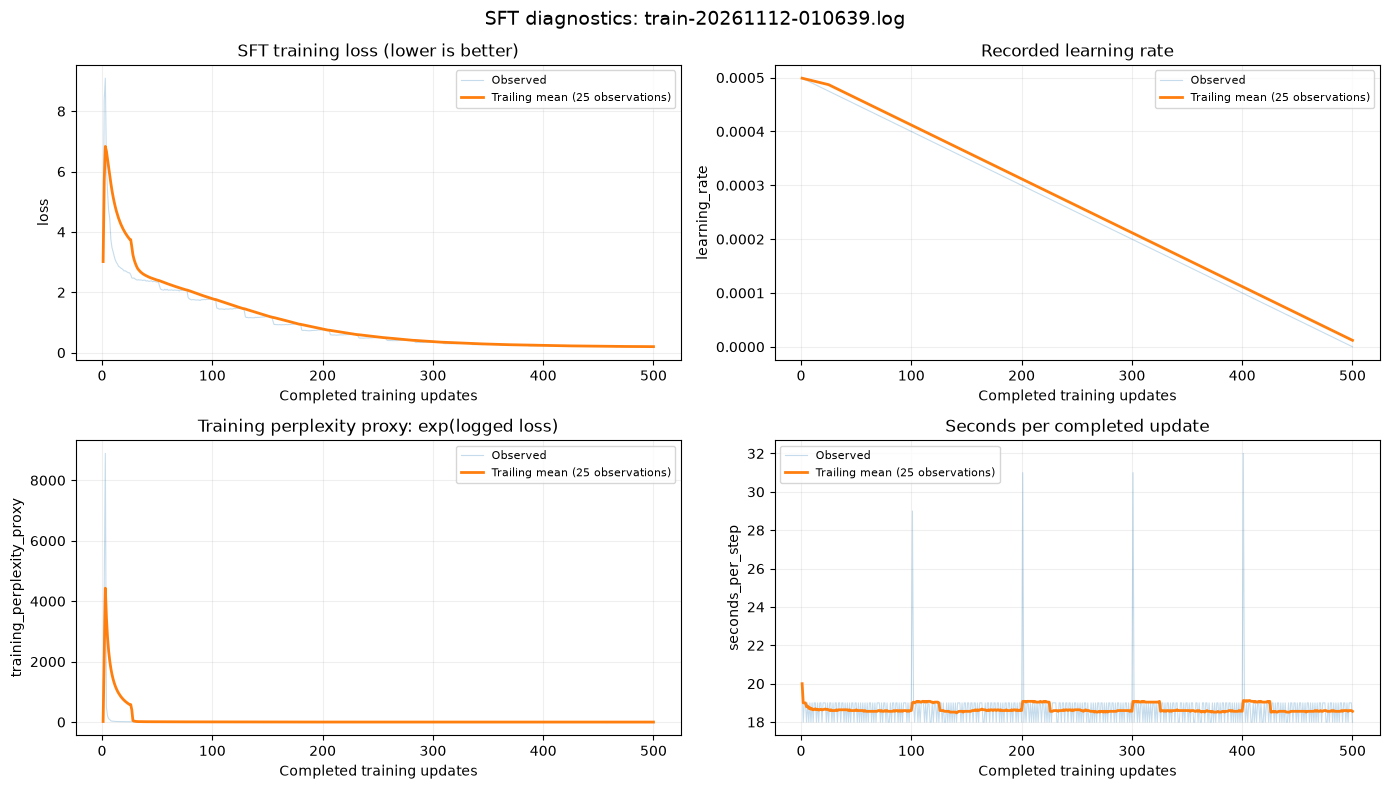

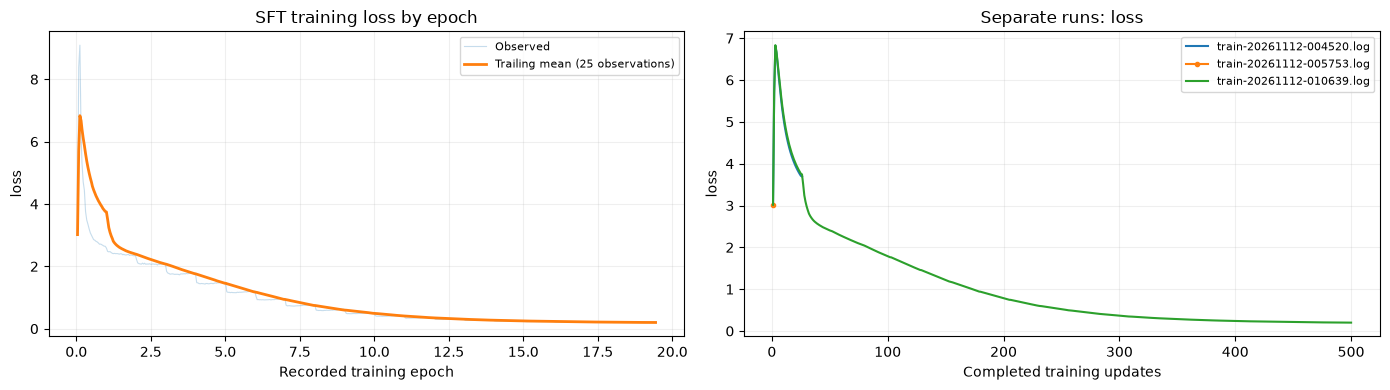

In [40]:
sft_dashboard, sft_axes = sft_plots.plot_dashboard()
plt.show()

sft_comparison, sft_comparison_axes = plt.subplots(1, 2, figsize=(14, 4))
sft_plots.plot_loss_by_epoch(ax=sft_comparison_axes[0])
sft_plots.plot_run_comparison('loss', ax=sft_comparison_axes[1])
sft_comparison.tight_layout()
plt.show()

## SFT reuse

- Individual plots: `sft_plots.plot_loss_curve(log_scale=True)`, `sft_plots.plot_learning_rate_curve()`, `sft_plots.plot_perplexity_curve(log_scale=True)`, `sft_plots.plot_loss_by_epoch()`, `sft_plots.plot_step_time()`; then `plt.show()`.
- Select another run with `SFTPlottingManager(sft_runs, run_name='train-20261112-004520.log', window=5)`. That interrupted run has 26 logged updates out of 50 and exit status 137; its curve is not appended to the 500-step run.
- `sft_runs.history`, `sft_runs.get_history()`, `sft_runs.run_info`, `sft_runs.final_results`, `sft_runs.config`, and `sft_runs.tokenizer_config` expose loaded artifacts. Root model/tokenizer/final metadata belong to the active run. `sft_runs.refresh()` reloads local files.
- `plot_metric('eval_loss')` and `plot_metric('grad_norm')` work only when those values are actually logged; otherwise they raise an explicit error. No SFT reward curve is synthesized.
- SFT and GFN use different losses and logging semantics. Their numerical loss scales must not be compared as if they were the same objective.

# Saved Story Cloze infilling evaluations

The cells below load the downloaded `results/` files; they do not load models or run inference. The general evaluation and the paper comparison use the same seeded held-out sample, with the latter a subset of the former.

This is adapted infilling with the correct ending supplied, not the official Story Cloze ending-choice task. The supplied training corpus was checked for normalized overlap, but broader pretraining contamination is unknown. The paper comparison is approximate, not an exact reproduction. General BERTScore is **unrescaled**; paper-comparison BERTScore is **rescaled**, so do not compare their values directly. BLEU and GLEU in the final table are percentages. Bootstrap intervals describe story-sampling uncertainty, not training variability.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RESULTS_DIR = RUN_DIR / 'results'

def load_experiment(directory):
    with (directory / 'evaluation_metadata.json').open() as file:
        metadata = json.load(file)
    rows = pd.read_json(directory / 'paired_results.jsonl', lines=True)
    required = {'story_id', 'sample_id', 'model', 'beginning', 'ending', 'reference_middle',
                'generated_middle', 'generated_tokens', 'stopped_on_eos', 'hit_length_cap',
                'bleu', 'gleu', 'bertscore_f1'}
    missing = required - set(rows.columns)
    if missing:
        raise ValueError(f'{directory}: missing result columns: {sorted(missing)}')
    if set(rows['model']) != {'SFT', 'GFN'} or rows.duplicated(['story_id', 'sample_id', 'model']).any():
        raise ValueError(f'{directory}: expected unique paired SFT and GFN outputs')
    counts = rows.groupby(['story_id', 'model']).size().unstack()
    expected_stories = metadata['dataset']['selected_stories']
    expected_samples = metadata['settings']['samples_per_story']
    if len(counts) != expected_stories or counts.isna().any().any() or not counts.eq(expected_samples).all().all():
        raise ValueError(f'{directory}: story or sample counts do not match metadata')
    pairs = rows.groupby(['story_id', 'sample_id'])['model'].nunique()
    if not pairs.eq(2).all():
        raise ValueError(f'{directory}: SFT/GFN outputs are not paired by story and sample')
    return rows, metadata

general, general_metadata = load_experiment(RESULTS_DIR / 'scored')
paper, paper_metadata = load_experiment(RESULTS_DIR / 'paper_comparison')
if not set(paper['story_id']).issubset(set(general['story_id'])):
    raise ValueError('Paper stories are not a subset of the general evaluation')
general_ci = pd.read_csv(RESULTS_DIR / 'confidence_intervals.csv')
paper_ci = pd.read_csv(RESULTS_DIR / 'paper_comparison' / 'confidence_intervals.csv')
paper_comparison = pd.read_csv(RESULTS_DIR / 'paper_comparison' / 'comparison.csv')
for name, frame, metadata in [('General', general, general_metadata), ('Paper', paper, paper_metadata)]:
    print(f"{name}: {frame['story_id'].nunique()} stories, "
          f"{metadata['settings']['samples_per_story']} samples per model per story, "
          f"{len(frame)} total outputs.")

def bootstrap_plot_intervals(frame, metrics, repetitions=10000, seed=0):
    grouped = frame.groupby(['story_id', 'model'])[metrics].mean().unstack('model')
    if len(grouped) < 2:
        raise ValueError('At least two stories are needed for bootstrap intervals')
    values = np.stack([grouped[metric][['SFT', 'GFN']].to_numpy(dtype=float)
                       for metric in metrics], axis=2)
    if not np.isfinite(values).all():
        raise ValueError('Plot metrics contain missing or non-finite story values')
    rng = np.random.default_rng(seed)
    draws = np.empty((repetitions, 3, len(metrics)))
    for start in range(0, repetitions, 250):
        size = min(250, repetitions - start)
        indices = rng.integers(0, len(grouped), size=(size, len(grouped)))
        means = values[indices].mean(axis=1)
        draws[start:start + size, :2] = means
        draws[start:start + size, 2] = means[:, 1] - means[:, 0]
    means = values.mean(axis=0)
    estimates = np.vstack([means, means[1] - means[0]])
    low, high = np.quantile(draws, [0.025, 0.975], axis=0)
    rows = []
    for i, comparison in enumerate(('SFT', 'GFN', 'GFN - SFT (paired)')):
        for j, metric in enumerate(metrics):
            rows.append({'metric': metric, 'comparison': comparison, 'stories': len(grouped),
                         'confidence': 0.95, 'estimate': estimates[i, j],
                         'ci_low': low[i, j], 'ci_high': high[i, j]})
    return pd.DataFrame(rows)

general_plot_ci = bootstrap_plot_intervals(
    general, ['generated_tokens', 'stopped_on_eos', 'hit_length_cap', 'bertscore_f1'])
paper_plot_data = paper.assign(bertscore_f1_rescaled=paper['bertscore_f1'],
                               bleu_4_percent=paper['bleu'] * 100,
                               gleu_4_percent=paper['gleu'] * 100)
paper_plot_ci = bootstrap_plot_intervals(
    paper_plot_data, ['bertscore_f1_rescaled', 'bleu_4_percent', 'gleu_4_percent'])

def plot_interval(table, metric, comparison, story_count):
    rows = table[(table['metric'] == metric) & (table['comparison'] == comparison)]
    if len(rows) != 1:
        raise ValueError(f'Expected one confidence interval for {metric}, {comparison}')
    row = rows.iloc[0]
    if row['stories'] != story_count or not np.isclose(row['confidence'], 0.95):
        raise ValueError(f'Confidence interval metadata does not match {metric}, {comparison}')
    if not np.isfinite(row[['estimate', 'ci_low', 'ci_high']].to_numpy(dtype=float)).all() or row['ci_low'] > row['ci_high']:
        raise ValueError(f'Invalid confidence interval for {metric}, {comparison}')
    return row

def draw_interval(ax, x, low, high, color='black'):
    ax.vlines(x, low, high, color=color, linewidth=1.5, zorder=5)
    ax.hlines([low, high], x - 0.045, x + 0.045, color=color, linewidth=1.5, zorder=5)

def paired_label(table, metric, story_count, scale=1, decimals=2):
    ci = plot_interval(table, metric, 'GFN - SFT (paired)', story_count)
    return (f"GFN − SFT: {ci['estimate'] * scale:.{decimals}f} "
            f"[{ci['ci_low'] * scale:.{decimals}f}, {ci['ci_high'] * scale:.{decimals}f}]")


General: 900 stories, 2 samples per model per story, 3600 total outputs.
Paper: 100 stories, 2 samples per model per story, 400 total outputs.


## General evaluation: examples and diagnostics

Examples show the same story and sample for both models. Histograms show output distributions; their legends give the story-averaged mean and 95% story-bootstrap interval, while titles give the paired GFN-minus-SFT difference and its interval. Termination bars show output-level percentages with 95% story-bootstrap intervals. Intervals are calculated from the downloaded outputs with 10,000 story resamples and seed 0. Narrow intervals may be difficult to see.

BERTScore curves are Gaussian kernel density estimates (Scott bandwidth) of the output-level scores, not normal-distribution fits. Paired Cohen's d_z is the mean GFN-minus-SFT difference divided by the standard deviation of the per-story differences, after averaging samples within each story. Token lengths remain a discrete histogram: the hard cap makes a smooth curve misleading. The distribution summary is descriptive; it does not treat the two samples per story as independent.

In [2]:
def print_paired_examples(frame, count=3):
    story_ids = frame['story_id'].drop_duplicates().head(count)
    for number, story_id in enumerate(story_ids, 1):
        story = frame[frame['story_id'] == story_id]
        sample_id = story['sample_id'].min()
        pair = story[story['sample_id'] == sample_id].set_index('model')
        reference = pair.loc['SFT']
        print(f"Example {number} (story {story_id[:12]}, sample {sample_id})")
        print(f"  Beginning: {reference['beginning']}")
        print(f"  Reference middle: {reference['reference_middle']}")
        print(f"  Ending: {reference['ending']}")
        for model in ('SFT', 'GFN'):
            print(f"  {model}: {pair.loc[model, 'generated_middle']}")
        print()

print_paired_examples(general)

Example 1 (story 13ed00d3826a, sample 0)
  Beginning: We went to Frank Pepe's pizza shop three weeks ago. The chain is quite famous in Connecticut. The chain recently opened in Boston.
  Reference middle: We went early to beat the crowd.
  Ending: We had a great pizza at Frank Pepe's pizza shop.
  SFT: We ate at a local pizza shop six miles away. It was a little sad, but we had a great pizza there.
  GFN: We went to the restaurant for a last bite.

Example 2 (story 341333cd9d7d, sample 0)
  Beginning: Frank did not want to do his homework. He wanted to play video games instead. Frank's parents told him to do his homework first.
  Reference middle: Frank threw a tantrum and got punished.
  Ending: Frank lost his video games for a week.
  SFT: Frank did his homework to earn money for video games. Now, Frank has video games and is happy. Frank is no longer
  GFN: Frank was forced to do his homework.

Example 3 (story b280cebdafb8, sample 0)
  Beginning: Sam wanted to throw a party. Sam in

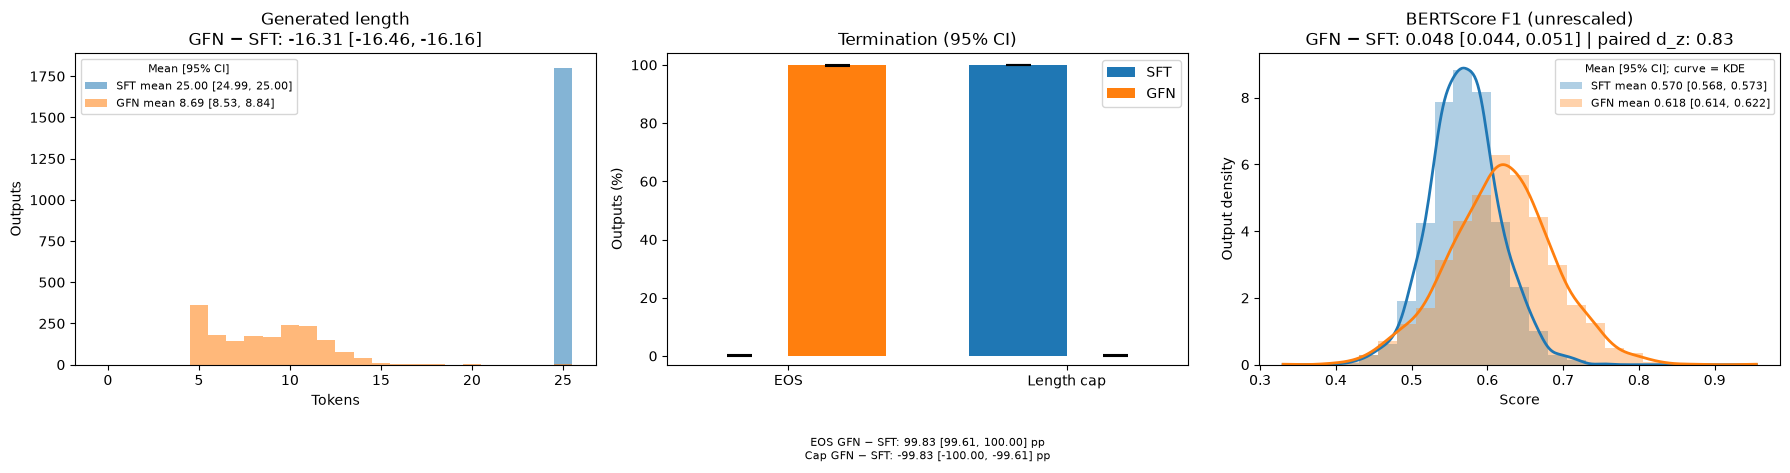

Output-level distribution summaries (samples from the same story are dependent):


Metric,Model,Outputs,Mean,SD,Median,25th percentile,75th percentile
generated_tokens,SFT,1800,24.997,0.141,25.000,25.000,25.000
generated_tokens,GFN,1800,8.689,2.900,9.000,6.000,11.000
bertscore_f1,SFT,1800,0.570,0.046,0.569,0.541,0.598
bertscore_f1,GFN,1800,0.618,0.070,0.619,0.573,0.662


In [2]:
def plot_general_diagnostics(frame, metadata):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    models = ('SFT', 'GFN')
    story_count = frame['story_id'].nunique()
    bins = np.arange(-0.5, metadata['settings']['max_new_tokens'] + 1.5)
    for model in models:
        values = frame.loc[frame['model'] == model, 'generated_tokens']
        ci = plot_interval(general_plot_ci, 'generated_tokens', model, story_count)
        if not np.isclose(values.mean(), ci['estimate']):
            raise ValueError(f'Length results and saved interval disagree for {model}')
        label = f"{model} mean {ci['estimate']:.2f} [{ci['ci_low']:.2f}, {ci['ci_high']:.2f}]"
        axes[0].hist(values, bins=bins, alpha=0.55, label=label)
    axes[0].set(title='Generated length\n' + paired_label(general_plot_ci, 'generated_tokens', story_count),
                xlabel='Tokens', ylabel='Outputs')
    axes[0].legend(fontsize=8, title='Mean [95% CI]', title_fontsize=8)

    positions = np.arange(2)
    for offset, model in enumerate(models):
        subset = frame[frame['model'] == model]
        rates = subset[['stopped_on_eos', 'hit_length_cap']].mean() * 100
        x_positions = positions + (offset - 0.5) * 0.35
        axes[1].bar(x_positions, rates, width=0.35, label=model)
        for x, metric, rate in zip(x_positions, ['stopped_on_eos', 'hit_length_cap'], rates):
            ci = plot_interval(general_plot_ci, metric, model, story_count)
            if not np.isclose(rate, ci['estimate'] * 100):
                raise ValueError(f'Termination results and saved interval disagree for {metric}, {model}')
            draw_interval(axes[1], x, ci['ci_low'] * 100, ci['ci_high'] * 100)
    axes[1].set_xticks(positions, ['EOS', 'Length cap'])
    axes[1].set(title='Termination (95% CI)', ylabel='Outputs (%)', ylim=(-3, 104))
    axes[1].legend()
    axes[1].text(0.5, -0.23,
                 'EOS ' + paired_label(general_plot_ci, 'stopped_on_eos', story_count, 100) + ' pp\n' +
                 'Cap ' + paired_label(general_plot_ci, 'hit_length_cap', story_count, 100) + ' pp',
                 transform=axes[1].transAxes, ha='center', va='top', fontsize=8)

    score_bins = np.histogram_bin_edges(frame['bertscore_f1'], bins=25)
    grid = np.linspace(score_bins[0], score_bins[-1], 300)
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    for index, model in enumerate(models):
        values = frame.loc[frame['model'] == model, 'bertscore_f1'].to_numpy(dtype=float)
        ci = plot_interval(general_plot_ci, 'bertscore_f1', model, story_count)
        if not np.isclose(values.mean(), ci['estimate']):
            raise ValueError(f'BERTScore results and interval disagree for {model}')
        label = f"{model} mean {ci['estimate']:.3f} [{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]"
        axes[2].hist(values, bins=score_bins, density=True, alpha=0.35, color=colors[index], label=label)
        bandwidth = values.std(ddof=1) * len(values) ** (-1 / 5)
        if bandwidth > 0:
            standardized = (grid[:, None] - values[None, :]) / bandwidth
            density = np.exp(-0.5 * standardized ** 2).mean(axis=1) / (bandwidth * np.sqrt(2 * np.pi))
            axes[2].plot(grid, density, color=colors[index], linewidth=2)
        else:
            axes[2].axvline(values[0], color=colors[index], linewidth=2,
                            label=f'{model}: constant score, KDE undefined')
    story_scores = frame.groupby(['story_id', 'model'])['bertscore_f1'].mean().unstack('model')
    differences = story_scores['GFN'] - story_scores['SFT']
    difference_sd = differences.std(ddof=1)
    effect = f"{differences.mean() / difference_sd:.2f}" if difference_sd > 0 else 'undefined (zero SD)'
    axes[2].set(title='BERTScore F1 (unrescaled)\n' +
                paired_label(general_plot_ci, 'bertscore_f1', story_count, decimals=3) +
                f' | paired d_z: {effect}',
                xlabel='Score', ylabel='Output density')
    axes[2].legend(fontsize=8, title='Mean [95% CI]; curve = KDE', title_fontsize=8)
    fig.tight_layout()
    plt.show()

    distribution_rows = []
    for metric in ('generated_tokens', 'bertscore_f1'):
        for model in models:
            values = frame.loc[frame['model'] == model, metric]
            distribution_rows.append({'Metric': metric, 'Model': model, 'Outputs': len(values),
                                      'Mean': values.mean(), 'SD': values.std(ddof=1),
                                      'Median': values.median(), '25th percentile': values.quantile(0.25),
                                      '75th percentile': values.quantile(0.75)})
    print('Output-level distribution summaries (samples from the same story are dependent):')
    display(pd.DataFrame(distribution_rows).style.format(
        {'Mean': '{:.3f}', 'SD': '{:.3f}', 'Median': '{:.3f}',
         '25th percentile': '{:.3f}', '75th percentile': '{:.3f}'}).hide(axis='index'))

plot_general_diagnostics(general, general_metadata)

## Paper comparison: examples and plots

These are saved results for the paper subset. Local error bars are 95% story-bootstrap intervals calculated from the downloaded outputs (10,000 resamples, seed 0). Titles also show the paired local GFN-minus-SFT difference with its 95% interval. Paper bars have no error bars because the paper's underlying data is unavailable. Prompting has no local result. BERTScore is rescaled, while BLEU and GLEU are percentages. Differences may reflect task and evaluation-protocol differences.

Example 1 (story 13ed00d3826a, sample 0)
  Beginning: We went to Frank Pepe's pizza shop three weeks ago. The chain is quite famous in Connecticut. The chain recently opened in Boston.
  Reference middle: We went early to beat the crowd.
  Ending: We had a great pizza at Frank Pepe's pizza shop.
  SFT: We ate at a local pizza shop six miles away. It was a little sad, but we had a great pizza there.
  GFN: We went to the restaurant for a last bite.

Example 2 (story 341333cd9d7d, sample 0)
  Beginning: Frank did not want to do his homework. He wanted to play video games instead. Frank's parents told him to do his homework first.
  Reference middle: Frank threw a tantrum and got punished.
  Ending: Frank lost his video games for a week.
  SFT: Frank did his homework to earn money for video games. Now, Frank has video games and is happy. Frank is no longer
  GFN: Frank was forced to do his homework.

Example 3 (story b280cebdafb8, sample 0)
  Beginning: Sam wanted to throw a party. Sam in

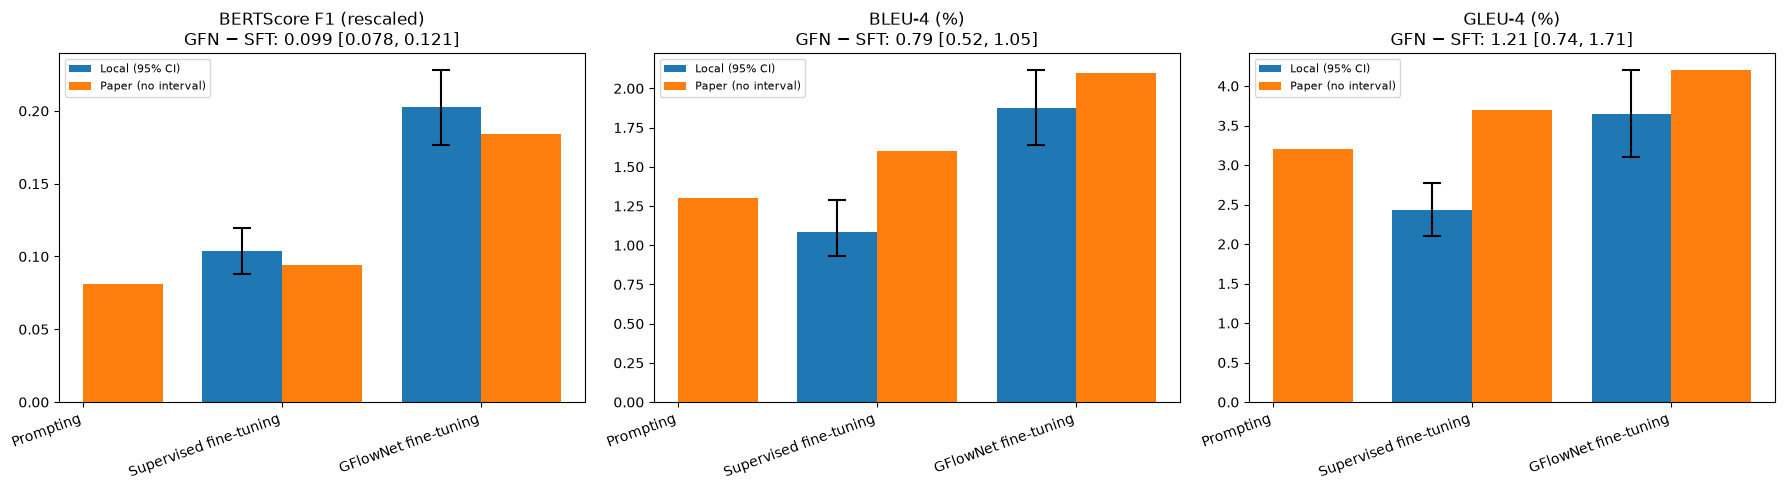

In [4]:
print_paired_examples(paper)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = [
    ('local_bertscore_f1_rescaled', 'paper_bertscore',
     'bertscore_f1_rescaled', 'BERTScore F1 (rescaled)', 3),
    ('local_bleu_4_percent', 'paper_bleu_4',
     'bleu_4_percent', 'BLEU-4 (%)', 2),
    ('local_gleu_4_percent', 'paper_gleu_4',
     'gleu_4_percent', 'GLEU-4 (%)', 2),
]
positions = np.arange(len(paper_comparison))
labels = paper_comparison['method'].tolist()
story_count = paper['story_id'].nunique()
for ax, (local_col, published_col, metric, title, decimals) in zip(axes, metrics):
    ax.bar(positions - 0.2, paper_comparison[local_col], width=0.4, label='Local (95% CI)')
    ax.bar(positions + 0.2, paper_comparison[published_col], width=0.4, label='Paper (no interval)')
    for position, (_, row) in zip(positions, paper_comparison.iterrows()):
        if pd.notna(row['local_model']):
            ci = plot_interval(paper_plot_ci, metric, row['local_model'], story_count)
            if not np.isclose(row[local_col], ci['estimate']):
                raise ValueError(f'Paper-subset results and saved interval disagree for {metric}, {row["local_model"]}')
            draw_interval(ax, position - 0.2, ci['ci_low'], ci['ci_high'])
    ax.set_xticks(positions, labels, rotation=20, ha='right')
    ax.set_title(title + '\n' + paired_label(paper_plot_ci, metric, story_count, decimals=decimals))
    ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

## Comparison table

Local intervals are the saved 95% story-bootstrap intervals; paper values are the reported point estimates. A dash means no local or paper value is available. The general and paper rows have different story counts and BERTScore scales.

In [5]:
def interval_lookup(frame, metric, model):
    selected = frame[(frame['metric'] == metric) & (frame['comparison'] == model)]
    if len(selected) != 1:
        raise ValueError(f'Expected one confidence interval for {metric}, {model}')
    return selected.iloc[0]

comparison_rows = []
general_metrics = [
    ('generated_tokens', 'Generated tokens', 1),
    ('stopped_on_eos', 'EOS rate (%)', 100),
    ('hit_length_cap', 'Length-cap rate (%)', 100),
    ('bleu', 'BLEU-4 (%)', 100),
    ('gleu', 'GLEU-4 (%)', 100),
    ('bertscore_f1', 'BERTScore F1 (unrescaled)', 1),
]
for metric, label, scale in general_metrics:
    for model in ('SFT', 'GFN'):
        ci = interval_lookup(general_ci, metric, model)
        comparison_rows.append({'Experiment': 'General', 'Stories': int(ci['stories']),
                                'Metric': label, 'Model / method': model,
                                'Local': ci['estimate'] * scale, '95% CI low': ci['ci_low'] * scale,
                                '95% CI high': ci['ci_high'] * scale, 'Paper': np.nan})

paper_metrics = [
    ('bertscore_f1_rescaled', 'BERTScore F1 (rescaled)', 'paper_bertscore'),
    ('bleu_4_percent', 'BLEU-4 (%)', 'paper_bleu_4'),
    ('gleu_4_percent', 'GLEU-4 (%)', 'paper_gleu_4'),
]
for metric, label, paper_column in paper_metrics:
    for _, reported in paper_comparison.iterrows():
        model = reported['local_model']
        ci = interval_lookup(paper_ci, metric, model) if pd.notna(model) else None
        comparison_rows.append({'Experiment': 'Paper subset',
                                'Stories': int(ci['stories']) if ci is not None else np.nan,
                                'Metric': label, 'Model / method': reported['method'],
                                'Local': ci['estimate'] if ci is not None else np.nan,
                                '95% CI low': ci['ci_low'] if ci is not None else np.nan,
                                '95% CI high': ci['ci_high'] if ci is not None else np.nan,
                                'Paper': reported[paper_column]})

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.style.format({'Stories': '{:.0f}', 'Local': '{:.3f}',
                                       '95% CI low': '{:.3f}', '95% CI high': '{:.3f}',
                                       'Paper': '{:.3f}'}, na_rep='—').hide(axis='index'))

Experiment,Stories,Metric,Model / method,Local,95% CI low,95% CI high,Paper
General,900,Generated tokens,SFT,24.997,24.990,25.000,—
General,900,Generated tokens,GFN,8.689,8.534,8.837,—
General,900,EOS rate (%),SFT,0.056,0.000,0.167,—
General,900,EOS rate (%),GFN,99.889,99.722,100.000,—
General,900,Length-cap rate (%),SFT,99.944,99.833,100.000,—
General,900,Length-cap rate (%),GFN,0.111,0.000,0.278,—
General,900,BLEU-4 (%),SFT,1.098,1.046,1.153,—
General,900,BLEU-4 (%),GFN,1.946,1.818,2.084,—
General,900,GLEU-4 (%),SFT,2.535,2.417,2.655,—
General,900,GLEU-4 (%),GFN,3.678,3.453,3.908,—


# Metric glossary

### Evaluation
- **Generated tokens:** non-EOS tokens in a generated middle.
- **EOS rate:** percentage of outputs that stopped by generating the end-of-sequence token.
- **Length-cap rate:** percentage that reached the maximum token limit without EOS.
- **BLEU-4:** smoothed 1–4-gram overlap with the reference, emphasizing precision; higher is better.
- **GLEU-4:** 1–4-gram overlap accounting for precision and recall against the reference; higher is better.
- **BERTScore F1:** contextual-token similarity between the generated and reference middles; higher is better. General scores are unrescaled; paper-subset scores are rescaled and are not directly comparable.
- **95% confidence interval:** story-bootstrap uncertainty interval around a local mean, not variability across training runs.

### Training diagnostics
- **GFN training loss:** modified-SubTB objective summed across accumulation batches; not directly comparable to SFT loss.
- **SFT training loss:** token-prediction loss on training batches. **Training perplexity proxy** is its exponential, not held-out perplexity.
- **Logged log reward:** temperature-scaled mean over prefixes and inactive zeros in the final microbatch; not terminal reward or held-out quality.
- **LogZ:** a normalizer parameter diagnostic; constant here because the active loss does not use it.
- **Learning rate / reward temperature:** training schedule settings, not measures of output quality.
- **Loss variability:** rolling standard deviation divided by the absolute rolling mean.
- **Seconds per update:** elapsed training time per completed update, including evaluation or checkpoint overhead when present.
- **Visible EOS / displayed words / unique prefixes:** proxies from truncated training-log examples, not exact token counts or a controlled diversity test.
- **KDE:** a smoothed estimate of the observed output-score density, not a significance test.
- **Paired Cohen's d_z:** mean paired per-story model difference divided by the standard deviation of those differences; its sign indicates the direction of GFN minus SFT.
- **SD / percentiles:** output-level spread and observed quantiles; samples within a story are dependent.